### Importing important libraries

In [54]:
import io
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

### 1. Data loading and understanding data & Basic data inspection

In [16]:
#first we will load the dataset and check the first few rows to understand its structure and contents.
data = pd.read_csv("student_placement_prediction_dataset_2026.csv")
data.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,83.411798,64.187246,1,1,550,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,88.956331,56.163678,1,4,833,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [17]:
'''lastly, we will check the last few rows of the dataset to ensure that the data is loaded correctly and to 
get a sense of the data distribution.'''
data.tail()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
99995,99996,21,Male,7.97,Mechanical,Tier 2,0,3,5,71.483407,56.904150,87.245760,43.013761,0,5,495,57.738311,75.471631,0,54.399022,66.446410,Yes,8.0,4.3,Placed,14.54
99996,99997,18,Female,7.79,CSE,Tier 1,1,1,2,78.960574,55.729008,42.767277,62.381626,0,2,958,80.076688,77.286948,1,33.692154,69.025632,Yes,4.4,3.1,Not Placed,0.00
99997,99998,20,Female,6.71,IT,Tier 2,2,4,4,66.691775,48.725390,72.394081,70.888580,0,6,272,70.797752,93.115933,0,64.989215,32.733645,Yes,7.6,2.9,Placed,13.45
99998,99999,19,Female,7.21,CSE,Tier 2,2,3,0,67.214893,79.336599,45.375535,52.091126,0,6,576,68.182555,71.306355,1,72.478779,32.205517,No,4.9,2.8,Not Placed,0.00
99999,100000,22,Female,8.58,ECE,Tier 3,1,3,2,92.146277,89.261932,81.629165,94.963205,0,1,812,77.864288,89.919640,0,48.363818,21.166444,Yes,6.5,2.9,Placed,14.43


In [18]:
''' Random samples of the dataset will be displayed to get a better understanding of the data and its 
characteristics.'''
data.sample(5)

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
83496,83497,20,Female,7.85,Civil,Tier 3,1,4,4,50.019220,38.674761,74.220002,50.581730,4,4,536,59.352636,83.949942,0,48.226544,70.760636,No,4.2,2.5,Placed,12.91
34207,34208,24,Female,6.93,EEE,Tier 2,3,4,2,31.211119,51.388224,90.211731,56.814105,0,6,955,64.911179,69.588746,1,81.775210,25.210159,No,3.5,3.9,Placed,11.20
13442,13443,22,Female,5.58,ECE,Tier 3,2,4,4,64.875226,66.677773,69.924383,55.893645,2,9,522,76.637922,73.452409,0,65.032364,67.322962,Yes,7.5,5.6,Not Placed,0.00
45654,45655,21,Female,4.50,CSE,Tier 2,2,3,3,99.558533,54.015506,79.297085,58.964645,0,7,268,86.424562,100.000000,0,57.403582,32.273494,No,5.2,2.3,Placed,13.50
78393,78394,20,Female,6.58,CSE,Tier 2,1,4,2,71.106409,73.779305,51.030184,74.188886,0,8,923,64.818427,70.503485,1,76.141568,80.410565,No,10.0,3.8,Not Placed,0.00


In [19]:
''' Identifying number of rows and columns in the dataset to understand its size and structure.'''
data.shape

(100000, 26)

In [20]:
''' checking column names and data types to understand the structure of the dataset and identify any potential 
issues with data types.'''
print("extracting info of dataset")
data.info()

extracting info of dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   student_id                 100000 non-null  int64  
 1   age                        100000 non-null  int64  
 2   gender                     100000 non-null  object 
 3   cgpa                       100000 non-null  float64
 4   branch                     100000 non-null  object 
 5   college_tier               100000 non-null  object 
 6   internships_count          100000 non-null  int64  
 7   projects_count             100000 non-null  int64  
 8   certifications_count       100000 non-null  int64  
 9   coding_skill_score         100000 non-null  float64
 10  aptitude_score             100000 non-null  float64
 11  communication_skill_score  100000 non-null  float64
 12  logical_reasoning_score    100000 non-null  float64
 13  hac

In [21]:
print("extracting description of dataset")
data.describe(include='all')

extracting description of dataset


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
count,100000.000000,100000.000000,100000,100000.000000,100000,100000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000,100000.000000,100000.000000,100000,100000.000000
unique,NaN,NaN,2,NaN,6,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,2,NaN
top,NaN,NaN,Male,NaN,CSE,Tier 2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,Placed,NaN
freq,NaN,NaN,60028,NaN,34818,49955,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59963,NaN,NaN,54459,NaN
mean,50000.500000,21.005740,NaN,7.496890,NaN,NaN,1.50223,3.001860,2.005150,69.825326,64.988108,67.960744,65.931696,1.000690,4.005160,524.559110,69.989411,84.730169,0.497590,59.894049,54.937526,NaN,6.983319,3.523124,NaN,7.252106
std,28867.657797,1.999562,NaN,0.992834,NaN,NaN,1.22528,1.731764,1.416553,14.694618,14.844093,13.846636,14.826790,0.997908,2.004897,274.993479,11.937257,9.416075,0.708434,19.549666,19.781197,NaN,1.468113,1.471248,NaN,6.735132
min,1.000000,18.000000,NaN,4.500000,NaN,NaN,0.00000,0.000000,0.000000,20.000000,20.000000,20.000000,20.000000,0.000000,0.000000,50.000000,20.000000,50.000000,0.000000,0.000000,0.000000,NaN,3.000000,0.500000,NaN,0.000000
25%,25000.750000,19.000000,NaN,6.820000,NaN,NaN,1.00000,2.000000,1.000000,59.807945,54.894600,58.587535,55.940547,0.000000,3.000000,287.000000,61.973172,78.325833,0.000000,46.538590,41.432390,NaN,6.000000,2.500000,NaN,0.000000
50%,50000.500000,21.000000,NaN,7.500000,NaN,NaN,1.00000,3.000000,2.000000,70.006250,65.011394,67.973221,66.003829,1.000000,4.000000,523.000000,70.026665,85.018828,0.000000,60.079021,55.076210,NaN,7.000000,3.500000,NaN,11.100000
75%,75000.250000,23.000000,NaN,8.180000,NaN,NaN,2.00000,4.000000,3.000000,80.058762,75.079266,77.503749,76.113705,2.000000,5.000000,764.000000,78.122083,91.782511,1.000000,73.549567,68.530115,NaN,8.000000,4.500000,NaN,13.470000


In [22]:
print("checking for null values")
data.isnull().sum()

checking for null values


student_id                   0
age                          0
gender                       0
cgpa                         0
branch                       0
college_tier                 0
internships_count            0
projects_count               0
certifications_count         0
coding_skill_score           0
aptitude_score               0
communication_skill_score    0
logical_reasoning_score      0
hackathons_participated      0
github_repos                 0
linkedin_connections         0
mock_interview_score         0
attendance_percentage        0
backlogs                     0
extracurricular_score        0
leadership_score             0
volunteer_experience         0
sleep_hours                  0
study_hours_per_day          0
placement_status             0
salary_package_lpa           0
dtype: int64

In [23]:
print("checking for duplicate rows")
data.duplicated().sum()

checking for duplicate rows


np.int64(0)

In [24]:
print("checking unique values in each column")
data.nunique()

checking unique values in each column


student_id                   100000
age                               7
gender                            2
cgpa                            551
branch                            6
college_tier                      3
internships_count                 9
projects_count                   14
certifications_count             12
coding_skill_score            97643
aptitude_score                98859
communication_skill_score     98872
logical_reasoning_score       98730
hackathons_participated           9
github_repos                     16
linkedin_connections            950
mock_interview_score          99352
attendance_percentage         93397
backlogs                          7
extracurricular_score         97660
leadership_score              98473
volunteer_experience              2
sleep_hours                      71
study_hours_per_day              92
placement_status                  2
salary_package_lpa             1047
dtype: int64

### Column-wise classification and target variable

The dataset is designed to predict whether a student gets placed. The important columns can be grouped as follows:

- Academic performance: cgpa, Attendance_percentage, Backlogs
- Technical ability: coding_skill_score, logical_reasoning_score, projects_count, hackathons_participated, github_repos, Aptitude_score
- Career preparation: internships_count, certifications_count, linkedin_connections, mock_interview_score
- Personal development: communication_skill_score, extracurricular_score, leadership_score, Volunteer_experience, sleep_hours, study_hours_per_day
- Placement outcome: placement_status, salary_package_lpa

Contextual columns like student_id, Age, gender, Branch, and college_tier are useful supporting attributes, but they are not direct measures of performance or placement. student_id should usually be dropped before model training because it is only an identifier.

#### Target variable
The target variable is placement_status.

This is the most important column because it is the outcome we want to predict: whether a student is Placed or Not Placed. All the other columns act as predictors or features that describe academic, technical, and career-related signals. The model learns patterns from these features to estimate the probability or label of placement_status, making it the central column for the prediction problem. salary_package_lpa is also a placement-related metric, but it is a secondary outcome and not the primary class label used for student placement prediction.


### 2. Now Data Cleaning

In [25]:
# Remove irrelevant columns and any target leakage from the dataset
columns_to_drop = ["student_id", "salary_package_lpa"]
data = data.drop(columns=columns_to_drop, errors="ignore")
data.head()

,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status
0,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed
1,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed
2,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed
3,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,83.411798,64.187246,1,1,550,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed
4,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,88.956331,56.163678,1,4,833,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed


### 3. Exploratory data analysis

Internship experience and placement status:

placement_status  Not Placed  Placed
has_internship                      
No                     11031   11172
Yes                    34510   43287


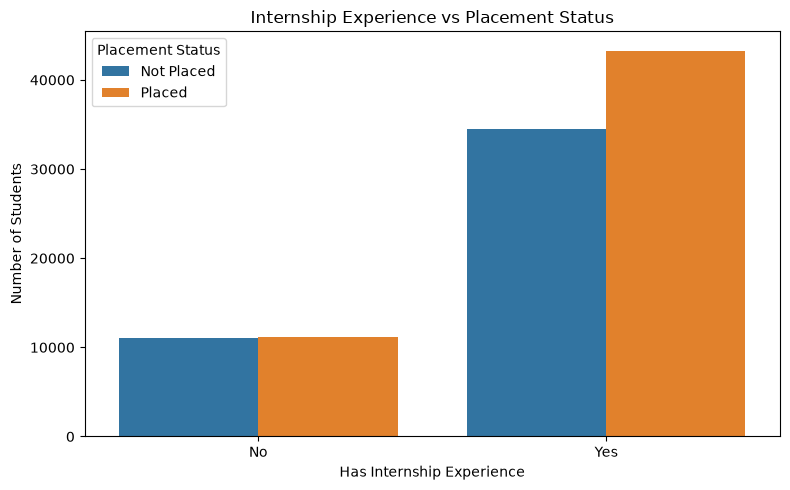

In [28]:
# Internship experience vs placement status
data["has_internship"] = data["internships_count"].apply(lambda x: "Yes" if x > 0 else "No")
internship_status = pd.crosstab(data["has_internship"], data["placement_status"]).reindex(index=["No", "Yes"], columns=["Not Placed", "Placed"], fill_value=0)
print("Internship experience and placement status:\n")
print(internship_status)
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="has_internship", hue="placement_status", order=["No", "Yes"], hue_order=["Not Placed", "Placed"])
plt.title("Internship Experience vs Placement Status")
plt.xlabel("Has Internship Experience")
plt.ylabel("Number of Students")
plt.legend(title="Placement Status")
plt.tight_layout()
plt.show()


CGPA statistics by placement status:

                  count      mean  median  min   max
placement_status                                    
Not Placed        45541  7.483789    7.49  4.5  10.0
Placed            54459  7.507846    7.51  4.5  10.0


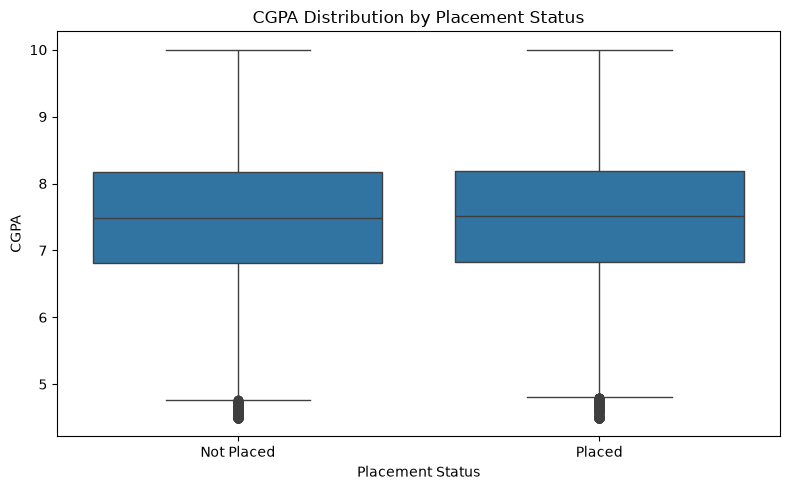

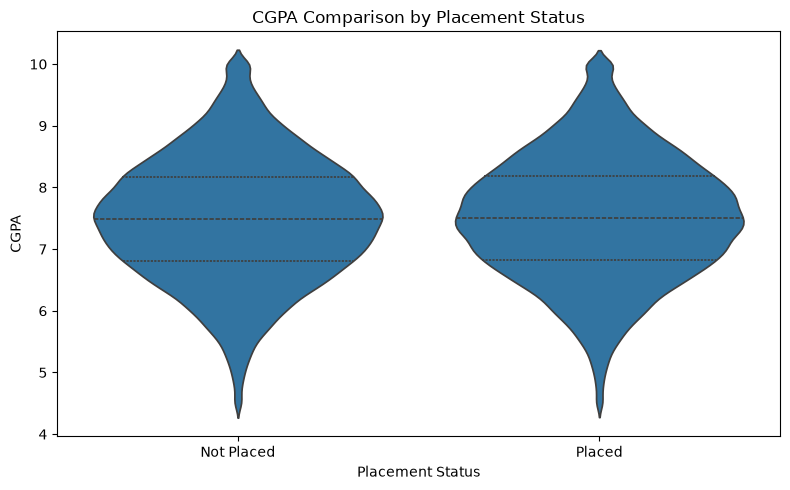

In [29]:
# Analyze CGPA vs placement status
placement_cgpa = data.groupby("placement_status")["cgpa"].agg(["count", "mean", "median", "min", "max"])
print("CGPA statistics by placement status:\n")
print(placement_cgpa)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="cgpa", order=["Not Placed", "Placed"])
plt.title("CGPA Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("CGPA")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="cgpa", order=["Not Placed", "Placed"], inner="quartile")
plt.title("CGPA Comparison by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("CGPA")
plt.tight_layout()
plt.show()


Project statistics by placement status:

                  count      mean  median  min  max
placement_status                                   
Not Placed        45541  2.886410     3.0    0   12
Placed            54459  3.098404     3.0    0   13


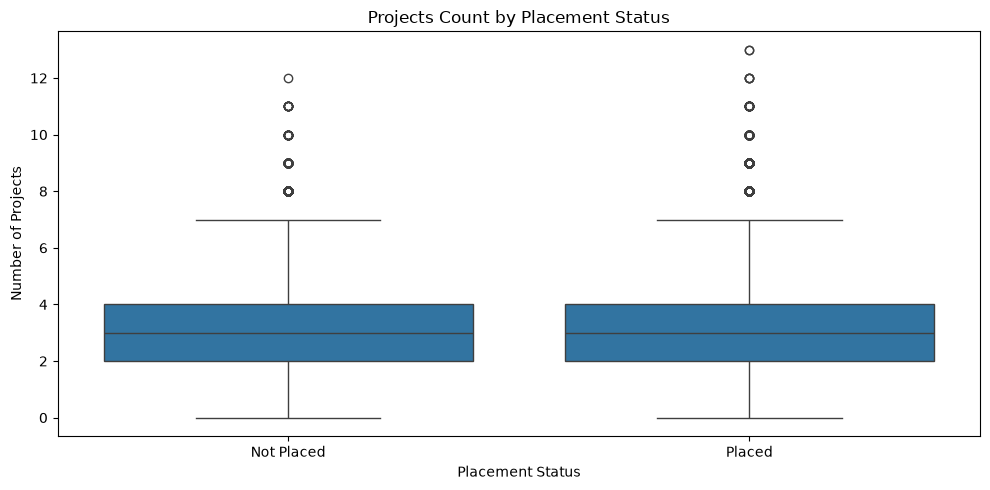

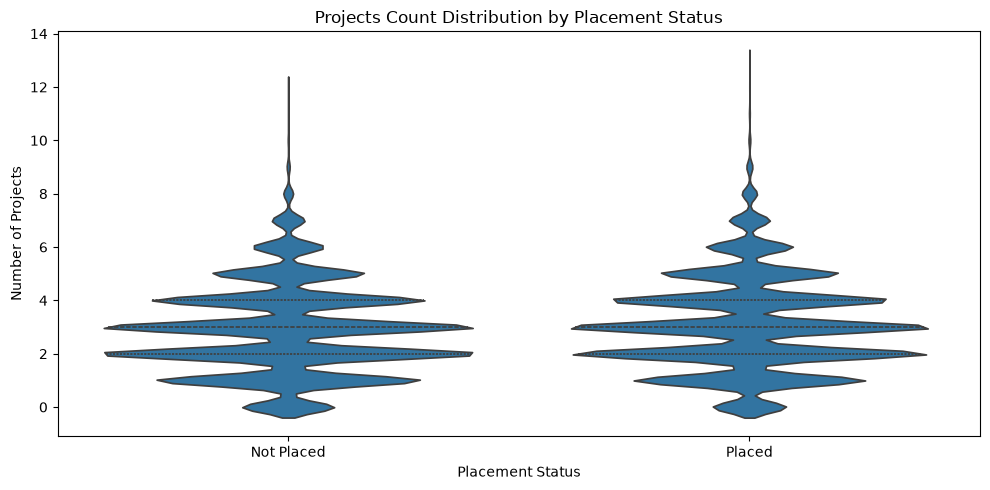

In [30]:
# Number of projects and placement status
project_summary = data.groupby("placement_status")["projects_count"].agg(["count", "mean", "median", "min", "max"])
print("Project statistics by placement status:\n")
print(project_summary)
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x="placement_status", y="projects_count", order=["Not Placed", "Placed"])
plt.title("Projects Count by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Number of Projects")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))
sns.violinplot(data=data, x="placement_status", y="projects_count", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Projects Count Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Number of Projects")
plt.tight_layout()
plt.show()


Coding skill statistics by placement status:

                  count       mean     median   min    max
placement_status                                          
Not Placed        45541  69.009449  69.149666  20.0  100.0
Placed            54459  70.507598  70.732405  20.0  100.0


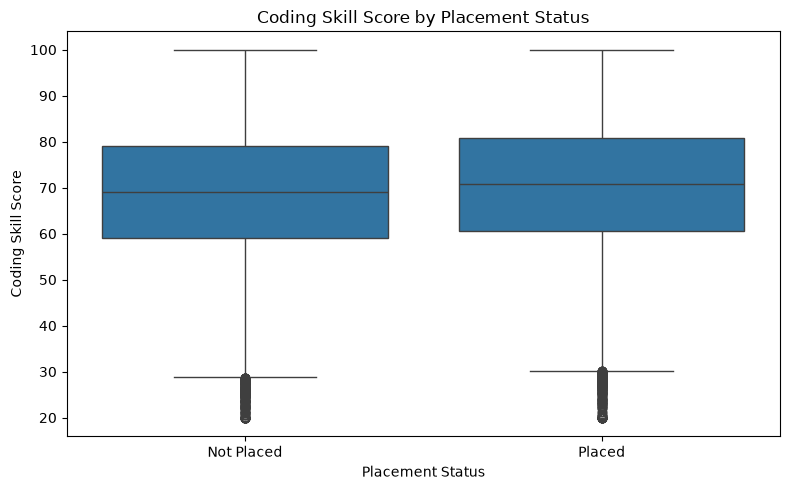

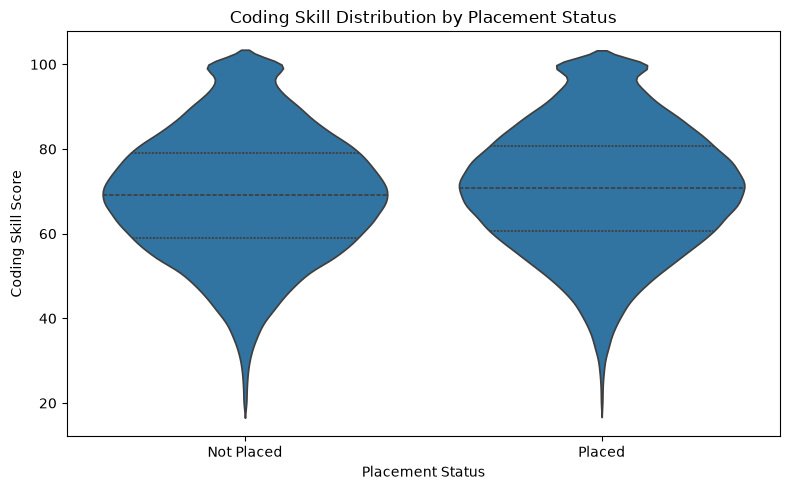

In [31]:
# Coding skill vs placement status
coding_skill_summary = data.groupby("placement_status")["coding_skill_score"].agg(["count", "mean", "median", "min", "max"])
print("Coding skill statistics by placement status:\n")
print(coding_skill_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="coding_skill_score", order=["Not Placed", "Placed"])
plt.title("Coding Skill Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Coding Skill Score")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="coding_skill_score", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Coding Skill Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Coding Skill Score")
plt.tight_layout()
plt.show()


Aptitude score statistics by placement status:

                  count       mean     median   min    max
placement_status                                          
Not Placed        45541  64.473703  64.416237  20.0  100.0
Placed            54459  65.418276  65.469800  20.0  100.0


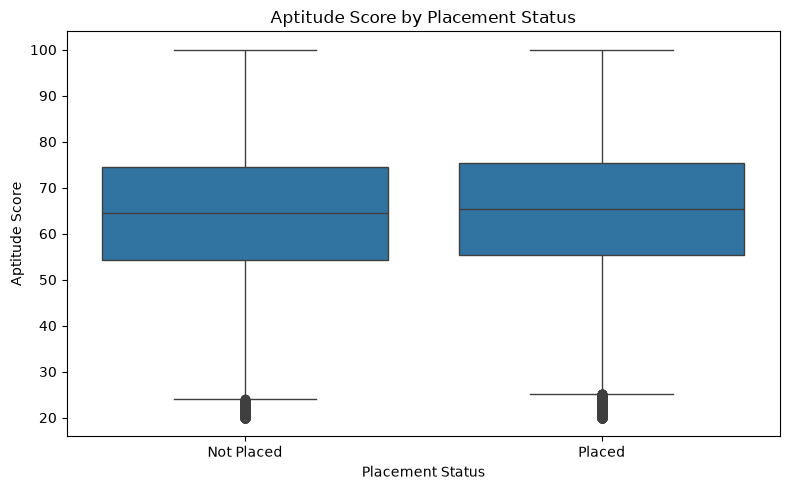

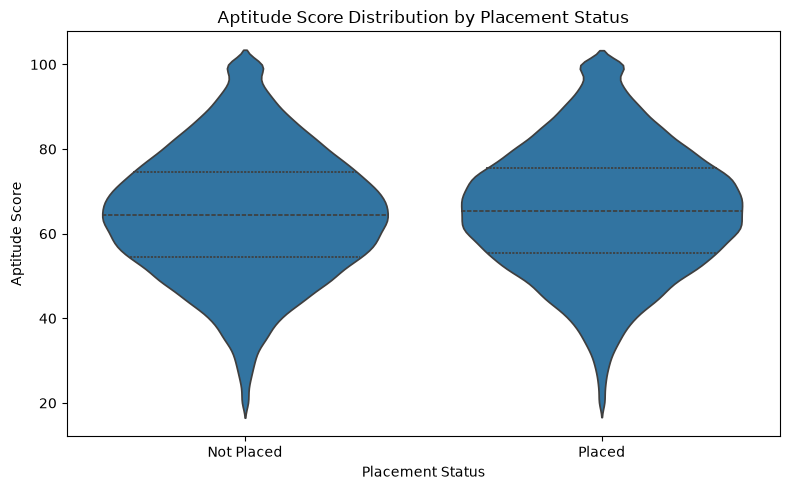

In [32]:
# Aptitude score vs placement status
aptitude_summary = data.groupby("placement_status")["aptitude_score"].agg(["count", "mean", "median", "min", "max"])
print("Aptitude score statistics by placement status:\n")
print(aptitude_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="aptitude_score", order=["Not Placed", "Placed"])
plt.title("Aptitude Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Aptitude Score")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="aptitude_score", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Aptitude Score Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Aptitude Score")
plt.tight_layout()
plt.show()


Communication skill statistics by placement status:

                  count       mean     median   min    max
placement_status                                          
Not Placed        45541  67.472542  67.448215  20.0  100.0
Placed            54459  68.368999  68.440795  20.0  100.0


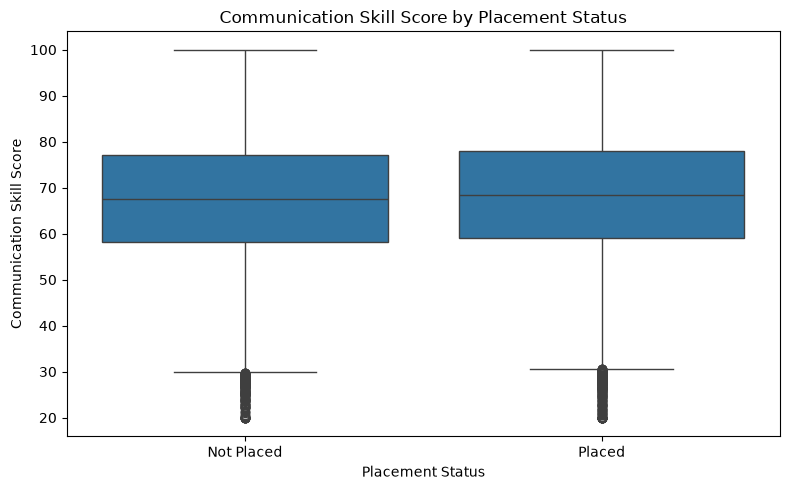

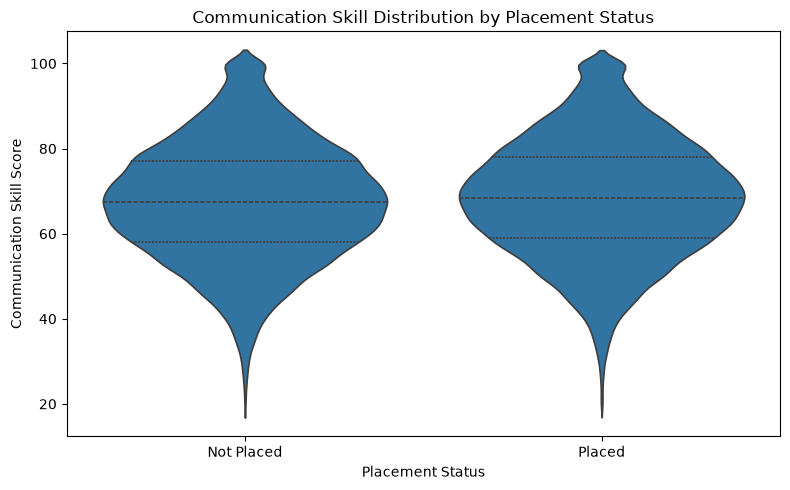

In [33]:
# Communication skill vs placement status
communication_summary = data.groupby("placement_status")["communication_skill_score"].agg(["count", "mean", "median", "min", "max"])
print("Communication skill statistics by placement status:\n")
print(communication_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="communication_skill_score", order=["Not Placed", "Placed"])
plt.title("Communication Skill Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Communication Skill Score")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="communication_skill_score", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Communication Skill Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Communication Skill Score")
plt.tight_layout()
plt.show()


Logical reasoning score statistics by placement status:

                  count       mean     median   min    max
placement_status                                          
Not Placed        45541  65.342630  65.414057  20.0  100.0
Placed            54459  66.424298  66.451542  20.0  100.0


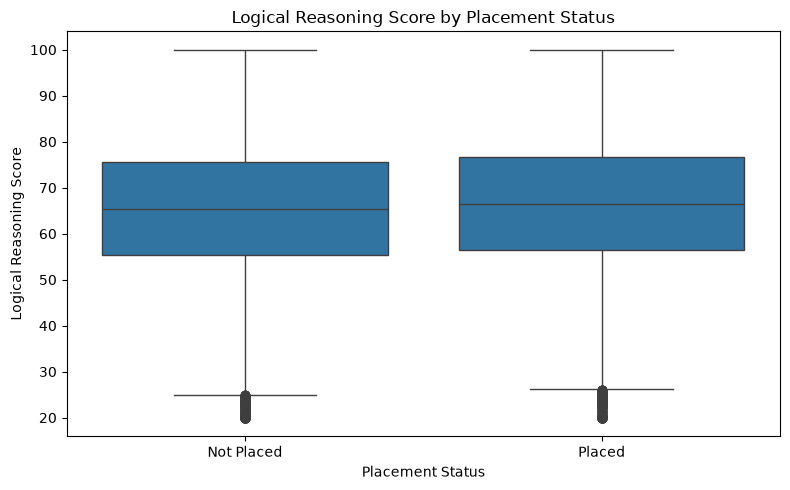

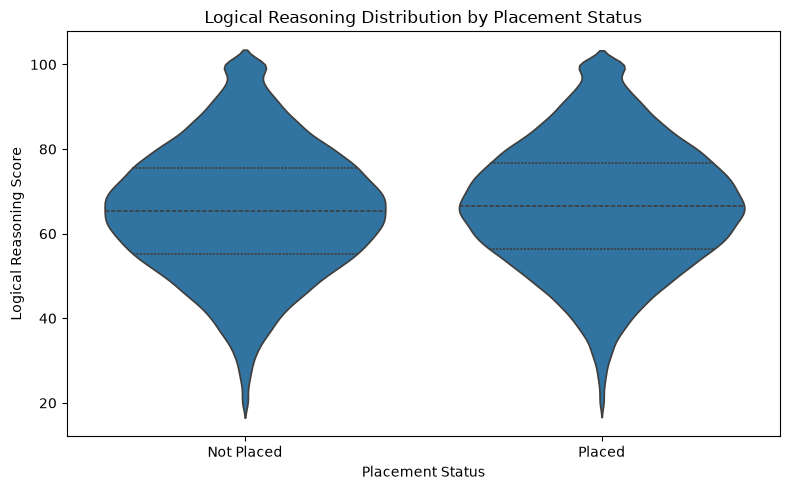

In [34]:
# Logical reasoning score vs placement status
logical_reasoning_summary = data.groupby("placement_status")["logical_reasoning_score"].agg(["count", "mean", "median", "min", "max"])
print("Logical reasoning score statistics by placement status:\n")
print(logical_reasoning_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="logical_reasoning_score", order=["Not Placed", "Placed"])
plt.title("Logical Reasoning Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Logical Reasoning Score")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="logical_reasoning_score", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Logical Reasoning Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Logical Reasoning Score")
plt.tight_layout()
plt.show()


Mock interview score statistics by placement status:

                  count       mean     median   min    max
placement_status                                          
Not Placed        45541  69.388182  69.394943  20.0  100.0
Placed            54459  70.492185  70.535418  20.0  100.0


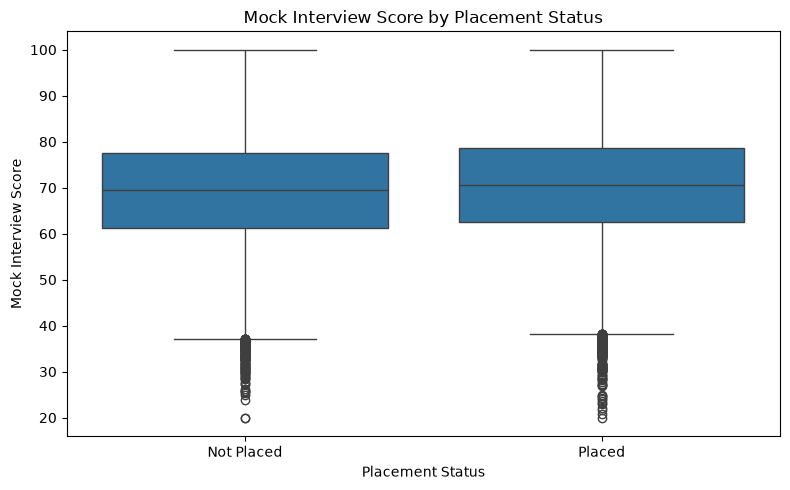

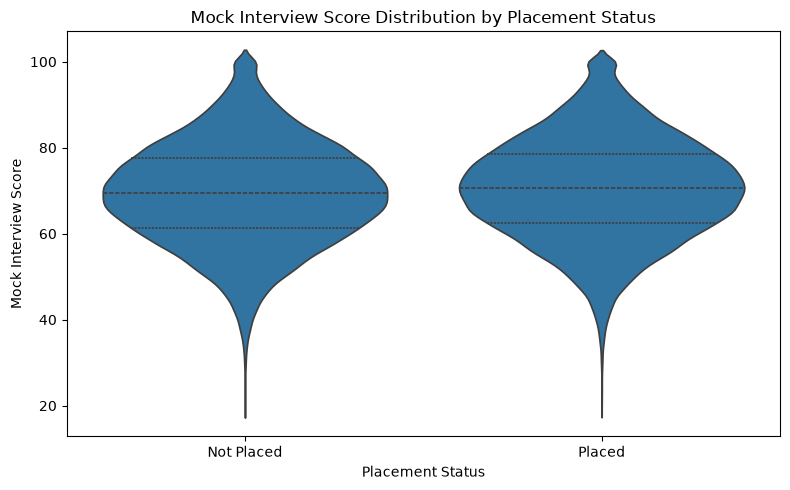

In [35]:
# Mock interview score vs placement status
mock_interview_summary = data.groupby("placement_status")["mock_interview_score"].agg(["count", "mean", "median", "min", "max"])
print("Mock interview score statistics by placement status:\n")
print(mock_interview_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="mock_interview_score", order=["Not Placed", "Placed"])
plt.title("Mock Interview Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Mock Interview Score")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="mock_interview_score", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Mock Interview Score Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Mock Interview Score")
plt.tight_layout()
plt.show()


Attendance percentage statistics by placement status:

                  count       mean     median   min    max
placement_status                                          
Not Placed        45541  84.816148  85.092182  50.0  100.0
Placed            54459  84.658270  84.961189  50.0  100.0


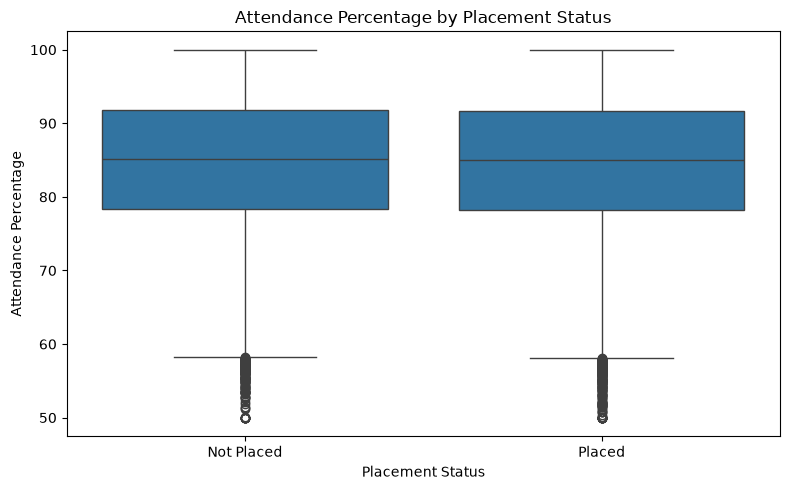

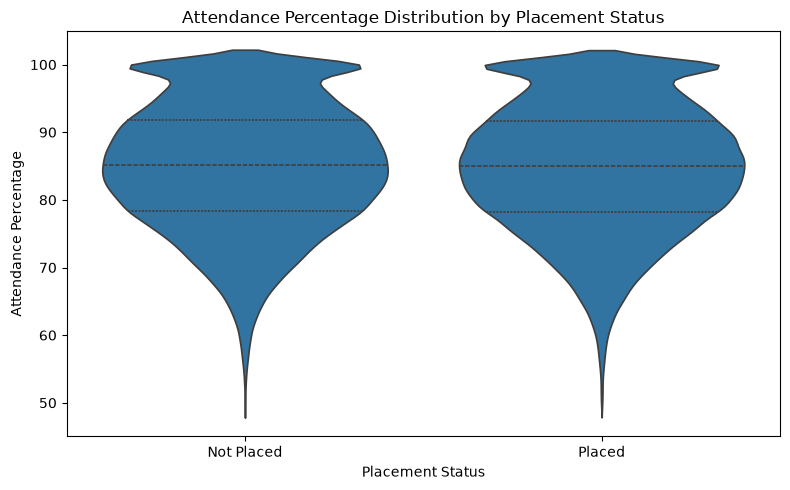

In [36]:
# Attendance percentage vs placement status
attendance_summary = data.groupby("placement_status")["attendance_percentage"].agg(["count", "mean", "median", "min", "max"])
print("Attendance percentage statistics by placement status:\n")
print(attendance_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="attendance_percentage", order=["Not Placed", "Placed"])
plt.title("Attendance Percentage by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Attendance Percentage")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="attendance_percentage", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Attendance Percentage Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Attendance Percentage")
plt.tight_layout()
plt.show()


Backlogs statistics by placement status:

                  count      mean  median  min  max
placement_status                                   
Not Placed        45541  0.561428     0.0    0    6
Placed            54459  0.444206     0.0    0    5


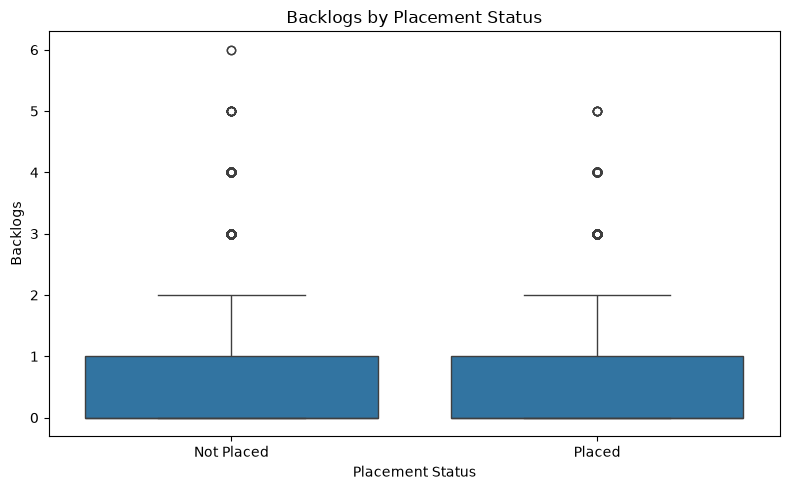

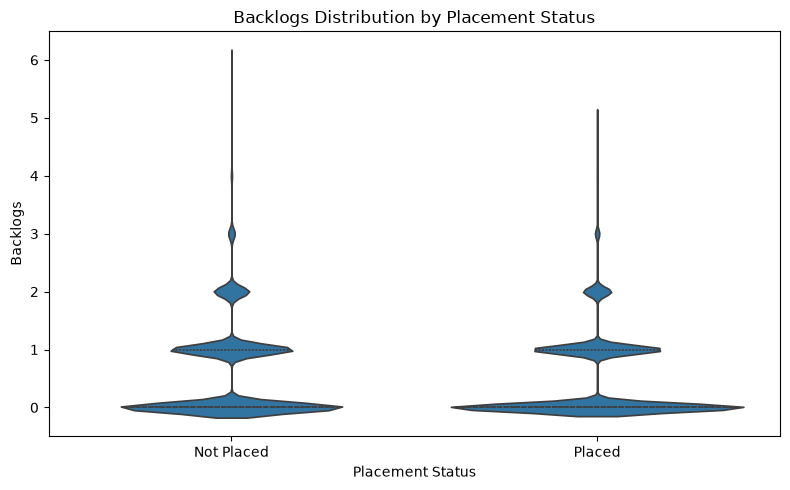

In [37]:
# Backlogs vs placement status
backlog_summary = data.groupby("placement_status")["backlogs"].agg(["count", "mean", "median", "min", "max"])
print("Backlogs statistics by placement status:\n")
print(backlog_summary)
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="placement_status", y="backlogs", order=["Not Placed", "Placed"])
plt.title("Backlogs by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Backlogs")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="placement_status", y="backlogs", order=["Not Placed", "Placed"], inner="quartile")
plt.title("Backlogs Distribution by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Backlogs")
plt.tight_layout()
plt.show()


### Additional factor analysis: college tier, branch, certifications, hackathons, GitHub, and leadership

This section checks whether several non-technical and participation-based factors appear to influence placement outcomes. We compare placement rates and distributions across categories and score-based features.

College tier vs placement status:

placement_status  Not Placed  Placed
college_tier                        
Tier 1                  9173   10988
Tier 2                 22837   27118
Tier 3                 13531   16353


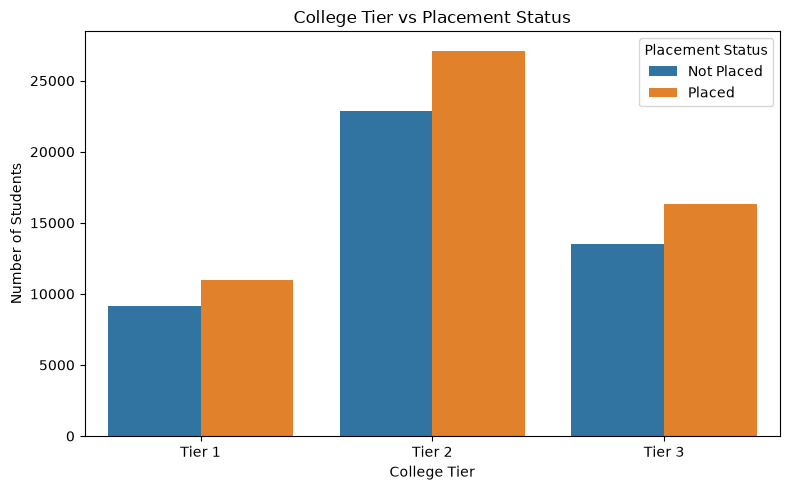


Placement rate by branch (% placed):
branch
Civil         55.174134
CSE           54.644150
EEE           54.318561
IT            54.302715
ECE           54.105178
Mechanical    54.083557
Name: placement_status, dtype: float64


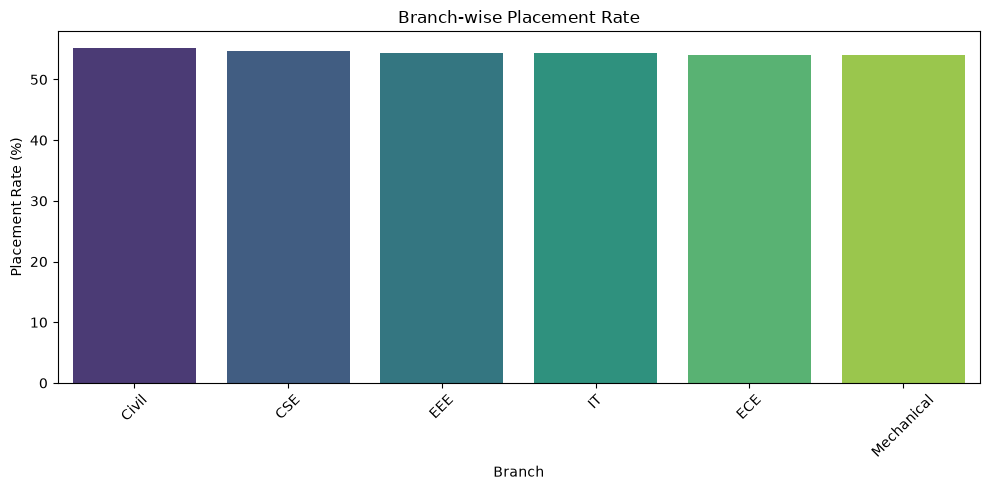

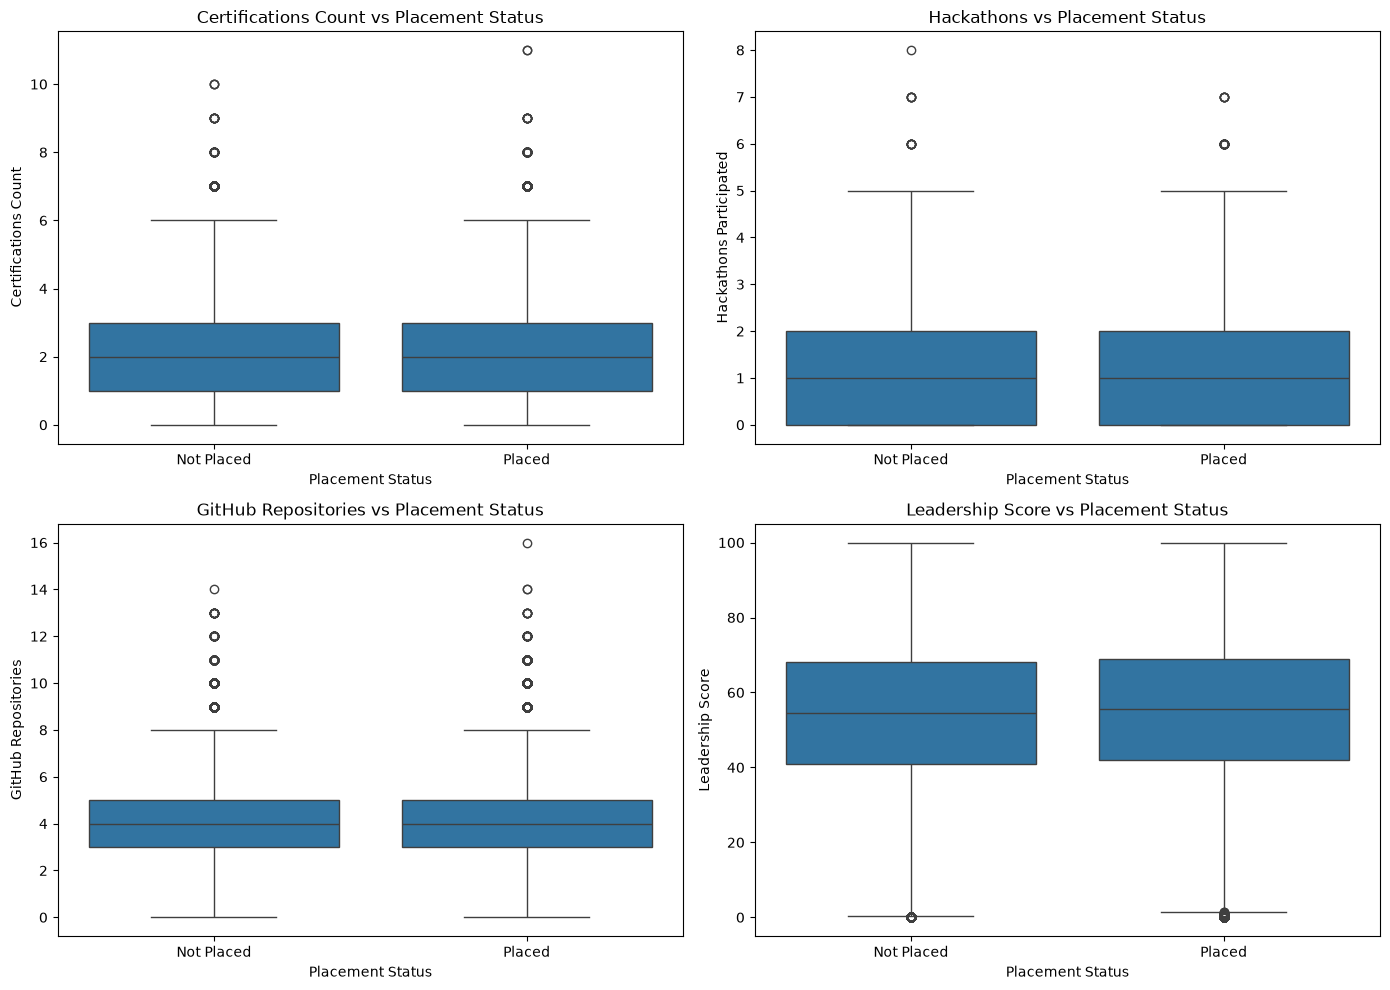


Average values of key factors by placement status:
                  certifications_count  hackathons_participated  github_repos  \
placement_status                                                                
Not Placed                    2.011045                 0.999341      3.994620   
Placed                        2.000220                 1.001818      4.013974   

                  leadership_score  
placement_status                    
Not Placed               54.457954  
Placed                   55.338565  


In [38]:
# College tier and branch analysis
tier_counts = pd.crosstab(data["college_tier"], data["placement_status"]).reindex(["Tier 1", "Tier 2", "Tier 3"], fill_value=0)
print("College tier vs placement status:\n")
print(tier_counts)
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="college_tier", hue="placement_status", order=["Tier 1", "Tier 2", "Tier 3"])
plt.title("College Tier vs Placement Status")
plt.xlabel("College Tier")
plt.ylabel("Number of Students")
plt.legend(title="Placement Status")
plt.tight_layout()
plt.show()

branch_rate = data.groupby("branch")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100).sort_values(ascending=False)
print("\nPlacement rate by branch (% placed):")
print(branch_rate)
plt.figure(figsize=(10, 5))
sns.barplot(x=branch_rate.index, y=branch_rate.values, palette="viridis")
plt.title("Branch-wise Placement Rate")
plt.xlabel("Branch")
plt.ylabel("Placement Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Certification, hackathons, GitHub, and leadership score analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.boxplot(data=data, x="placement_status", y="certifications_count", order=["Not Placed", "Placed"], ax=axes[0, 0])
axes[0, 0].set_title("Certifications Count vs Placement Status")
axes[0, 0].set_xlabel("Placement Status")
axes[0, 0].set_ylabel("Certifications Count")

sns.boxplot(data=data, x="placement_status", y="hackathons_participated", order=["Not Placed", "Placed"], ax=axes[0, 1])
axes[0, 1].set_title("Hackathons vs Placement Status")
axes[0, 1].set_xlabel("Placement Status")
axes[0, 1].set_ylabel("Hackathons Participated")

sns.boxplot(data=data, x="placement_status", y="github_repos", order=["Not Placed", "Placed"], ax=axes[1, 0])
axes[1, 0].set_title("GitHub Repositories vs Placement Status")
axes[1, 0].set_xlabel("Placement Status")
axes[1, 0].set_ylabel("GitHub Repositories")

sns.boxplot(data=data, x="placement_status", y="leadership_score", order=["Not Placed", "Placed"], ax=axes[1, 1])
axes[1, 1].set_title("Leadership Score vs Placement Status")
axes[1, 1].set_xlabel("Placement Status")
axes[1, 1].set_ylabel("Leadership Score")

plt.tight_layout()
plt.show()

# Additional summary of mean values for these factors
factor_summary = data.groupby("placement_status")[["certifications_count", "hackathons_participated", "github_repos", "leadership_score"]].mean()
print("\nAverage values of key factors by placement status:")
print(factor_summary)


#### Important patterns observed

- College tier and branch show almost flat placement rates, with values staying around 54-55% across groups. This suggests they do not strongly determine placement outcomes by themselves.
- Certification count, hackathons, GitHub repositories, and leadership score show only small differences between placed and not-placed students. For example, placed students average slightly more GitHub repositories and leadership scores, but the gap is modest rather than dramatic.
- The data suggests these factors may provide some incremental advantage, but they are not the primary differentiators. More decisive signals are likely the performance-based measures such as CGPA, coding skill, aptitude, mock interview, and communication scores.
- In short, participation and background factors may help, but they appear to be weaker predictors than technical and assessment performance metrics.

### Now Feature Relationship and Correlation Analysis

### 4. Relationship analysis among numerical features

This section examines how the numeric variables in the dataset relate to each other and which of them have the strongest association with placement success.

Correlation matrix for numeric features:

                             age   cgpa  internships_count  projects_count  \
age                        1.000  0.004              0.003          -0.002   
cgpa                       0.004  1.000              0.004           0.004   
internships_count          0.003  0.004              1.000           0.001   
projects_count            -0.002  0.004              0.001           1.000   
certifications_count      -0.000 -0.001             -0.003           0.002   
coding_skill_score         0.001  0.004             -0.003          -0.004   
aptitude_score            -0.001 -0.003              0.001          -0.001   
communication_skill_score -0.000  0.004             -0.002          -0.002   
logical_reasoning_score    0.001 -0.002             -0.000          -0.005   
hackathons_participated    0.001 -0.002              0.000           0.001   
github_repos              -0.002 -0.002              0.000          -0.001   
linkedin_connections  

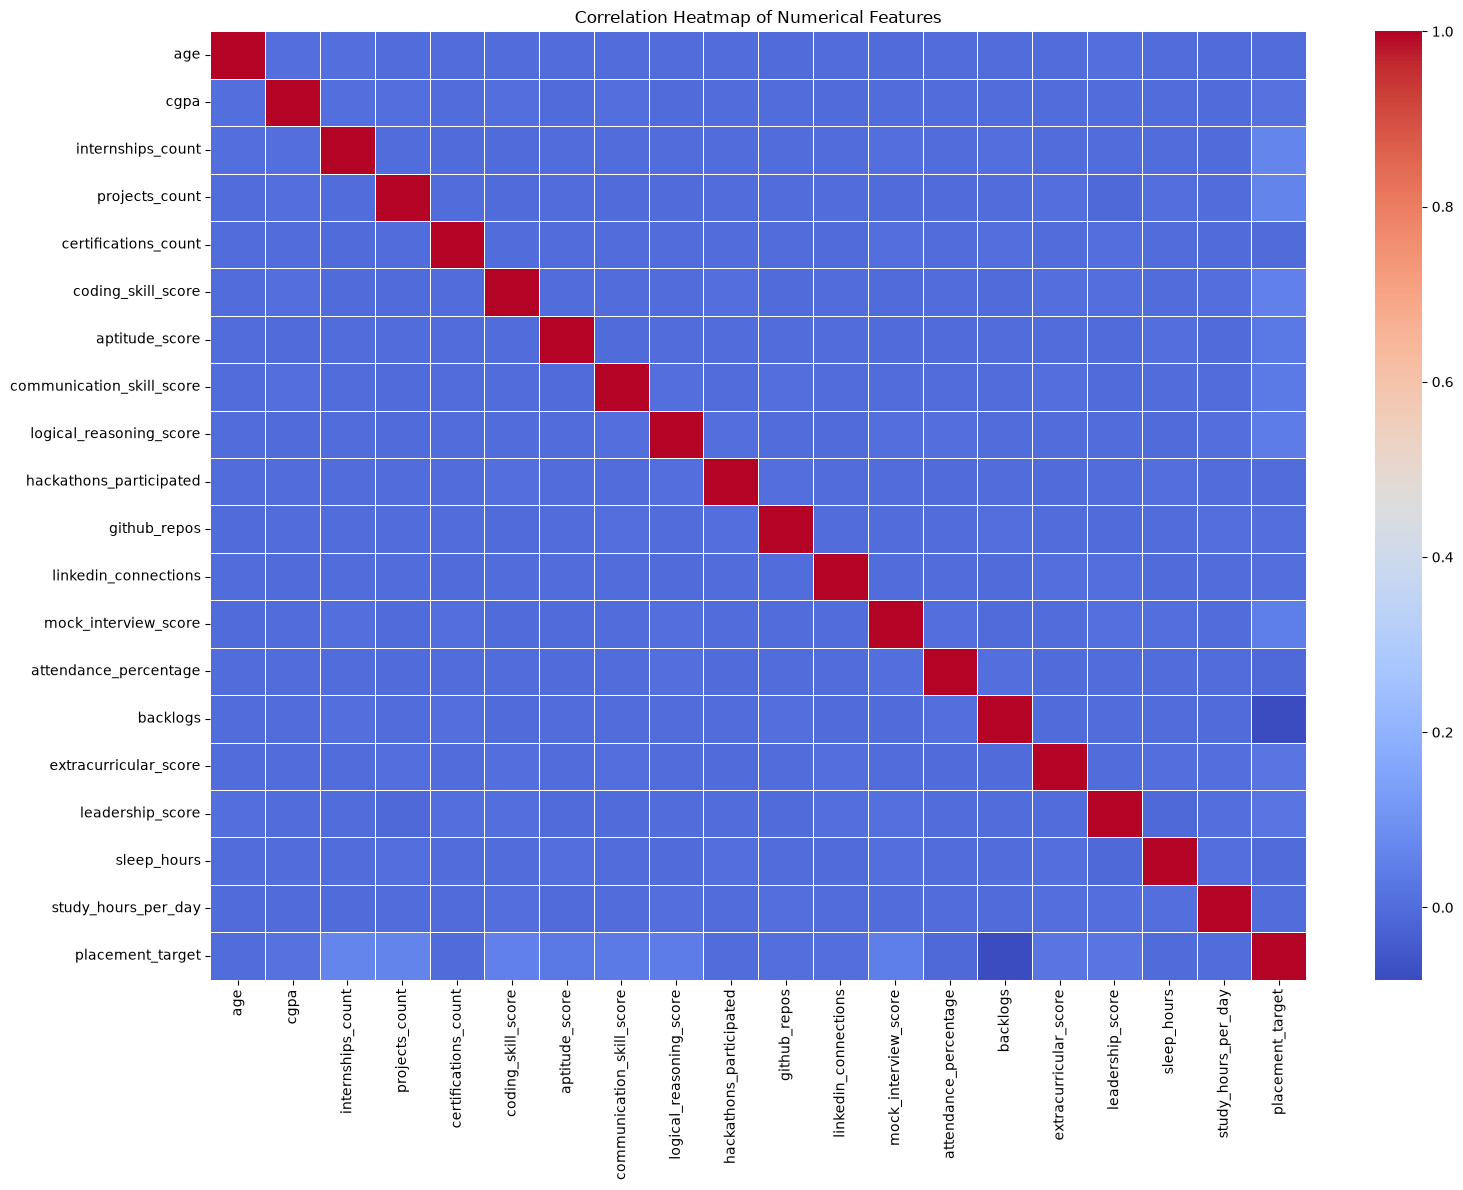


Top correlations with placement status:

internships_count            0.063
projects_count               0.061
coding_skill_score           0.051
mock_interview_score         0.046
logical_reasoning_score      0.036
communication_skill_score    0.032
aptitude_score               0.032
leadership_score             0.022
extracurricular_score        0.020
cgpa                         0.012
Name: placement_target, dtype: float64

Strongest feature-to-feature correlations:

internships_count          placement_target    0.063
projects_count             placement_target    0.061
coding_skill_score         placement_target    0.051
mock_interview_score       placement_target    0.046
logical_reasoning_score    placement_target    0.036
communication_skill_score  placement_target    0.032
aptitude_score             placement_target    0.032
leadership_score           placement_target    0.022
extracurricular_score      placement_target    0.020
cgpa                       placement_target    

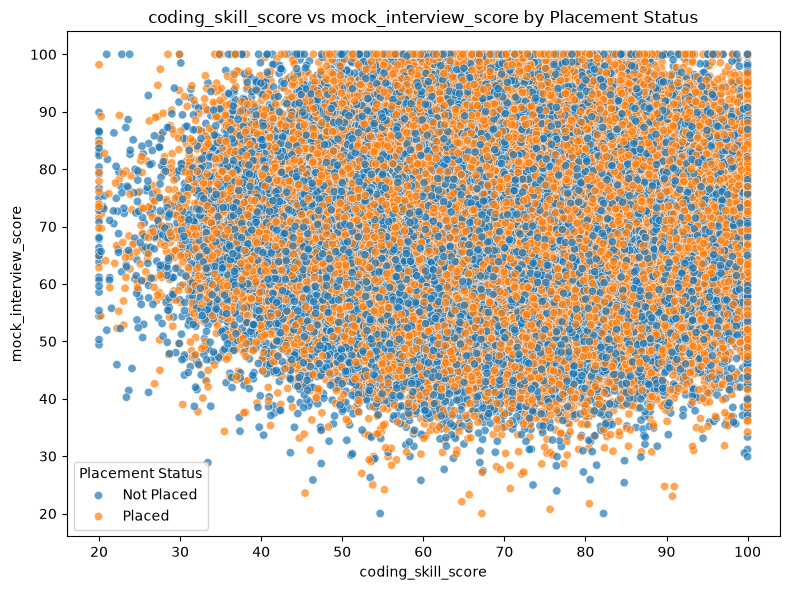

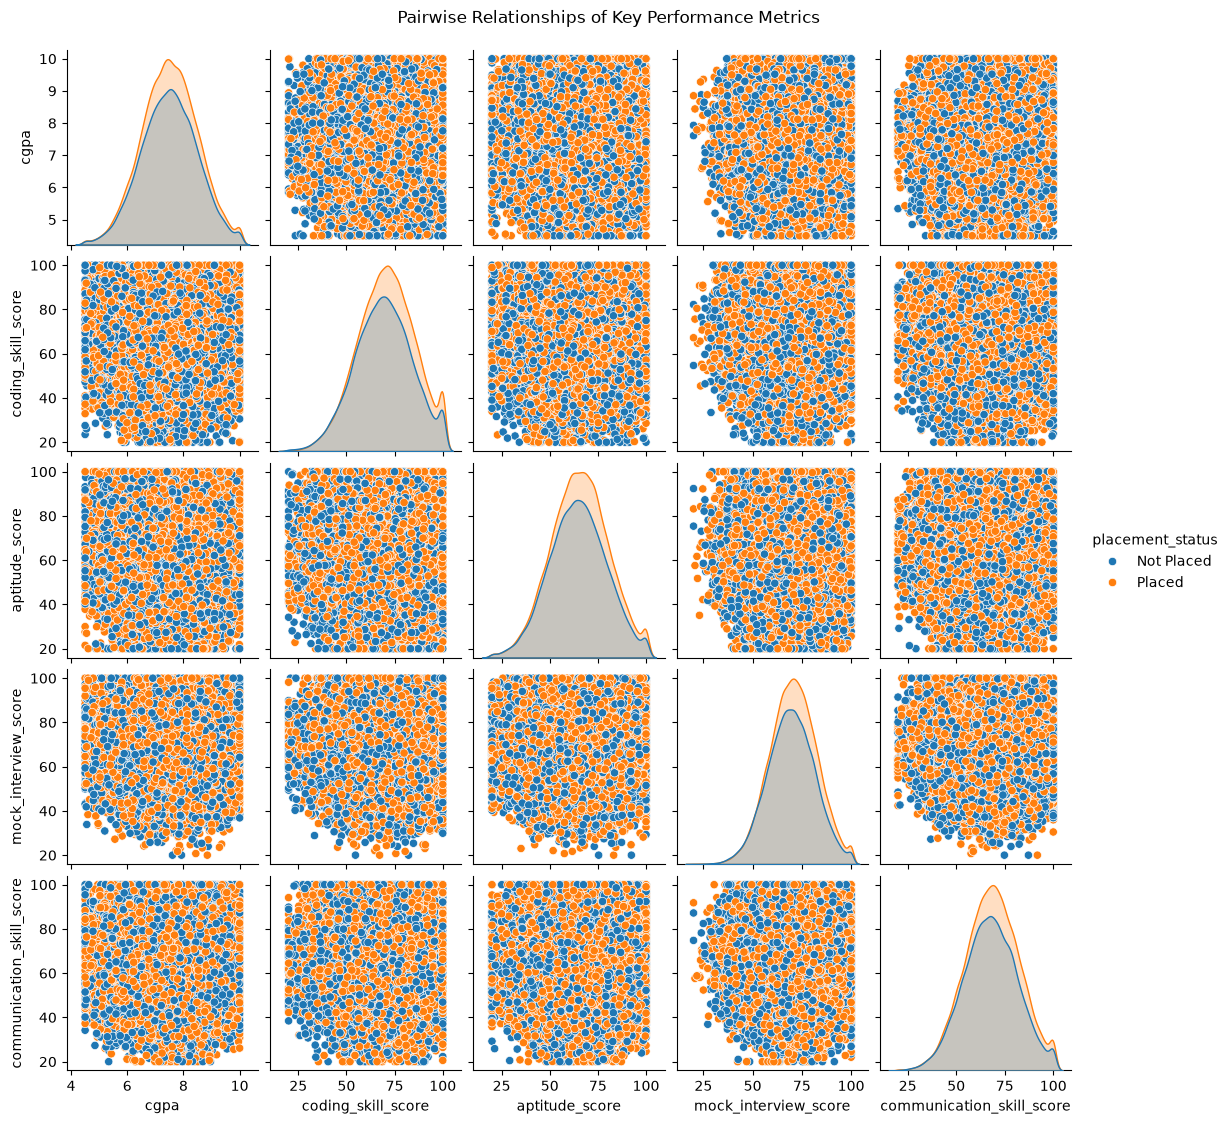

In [39]:
# Analyze relationships among numerical features
numeric_df = data.select_dtypes(include=["number"]).copy()
numeric_df["placement_target"] = data["placement_status"].map({"Placed": 1, "Not Placed": 0})
corr_matrix = numeric_df.corr()
print("Correlation matrix for numeric features:\n")
print(corr_matrix.round(3))

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

target_corr = corr_matrix["placement_target"].sort_values(ascending=False).drop(labels=["placement_target"])
print("\nTop correlations with placement status:\n")
print(target_corr.head(10).round(3))

strong_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("\nStrongest feature-to-feature correlations:\n")
print(strong_pairs.head(10).round(3))

# Scatter plot for the strongest numeric relationships
top_feature_1, top_feature_2 = "coding_skill_score", "mock_interview_score"
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x=top_feature_1, y=top_feature_2, hue="placement_status", alpha=0.7)
plt.title(f"{top_feature_1} vs {top_feature_2} by Placement Status")
plt.xlabel(top_feature_1)
plt.ylabel(top_feature_2)
plt.legend(title="Placement Status")
plt.tight_layout()
plt.show()

# Pairplot for the most relevant performance metrics
selected_cols = ["cgpa", "coding_skill_score", "aptitude_score", "mock_interview_score", "communication_skill_score", "placement_target"]
sns.pairplot(numeric_df[selected_cols].assign(placement_status=data["placement_status"]), vars=["cgpa", "coding_skill_score", "aptitude_score", "mock_interview_score", "communication_skill_score"], hue="placement_status", diag_kind="kde", height=2.2)
plt.suptitle("Pairwise Relationships of Key Performance Metrics", y=1.02)
plt.show()


### Correlation analysis: which features relate most to placement outcomes?

This analysis checks how strongly each numeric feature is associated with placement status.

Top correlations with placement status:

internships_count            0.0635
projects_count               0.0610
coding_skill_score           0.0508
mock_interview_score         0.0461
logical_reasoning_score      0.0363
communication_skill_score    0.0322
aptitude_score               0.0317
leadership_score             0.0222
extracurricular_score        0.0201
cgpa                         0.0121
github_repos                 0.0048
linkedin_connections         0.0032
hackathons_participated      0.0012
age                          0.0009
study_hours_per_day         -0.0014
certifications_count        -0.0038
sleep_hours                 -0.0047
attendance_percentage       -0.0084
backlogs                    -0.0824
Name: placement_target, dtype: float64


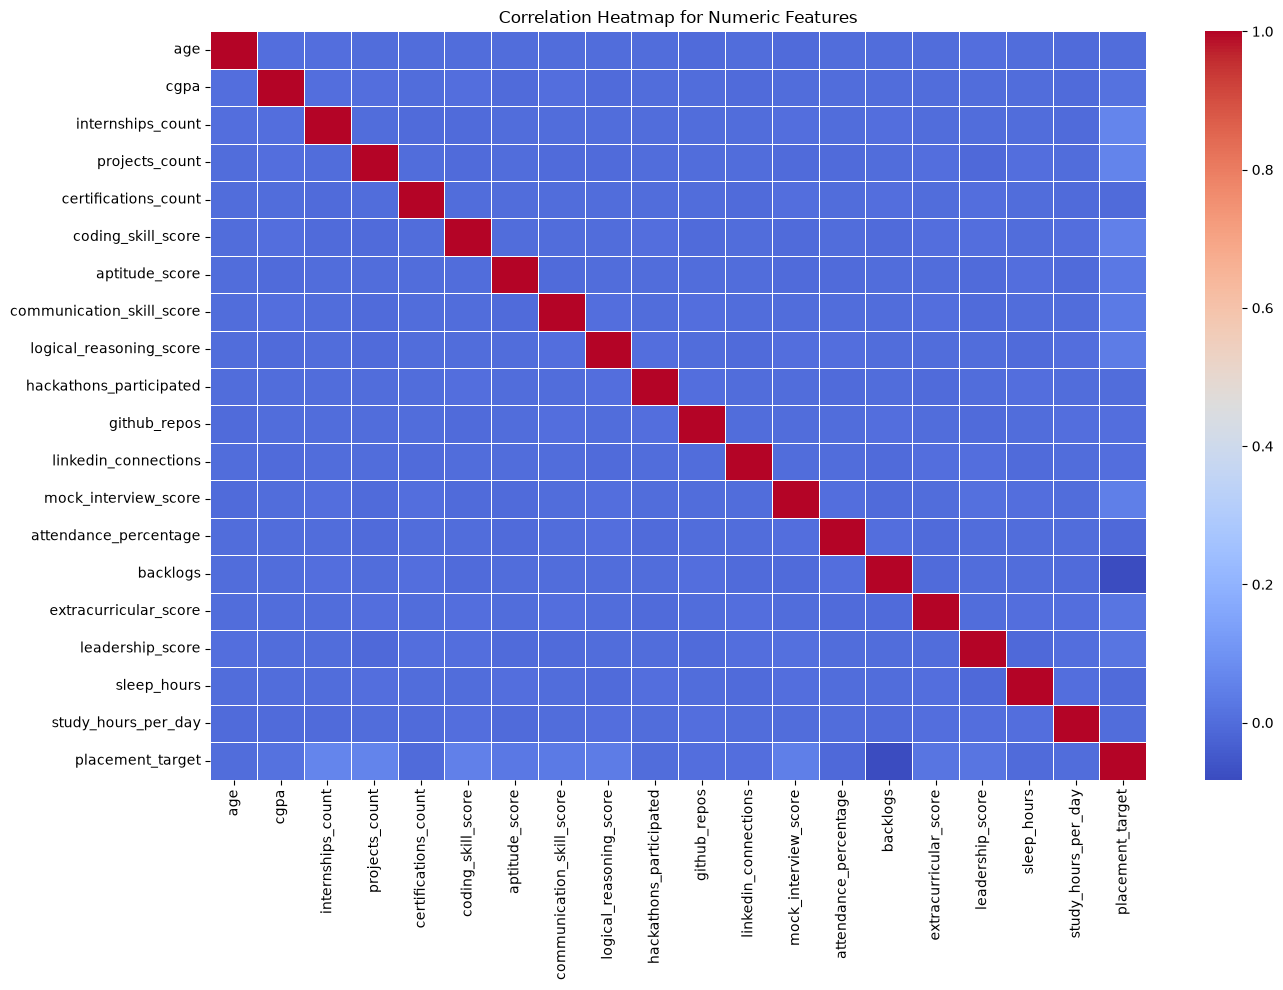

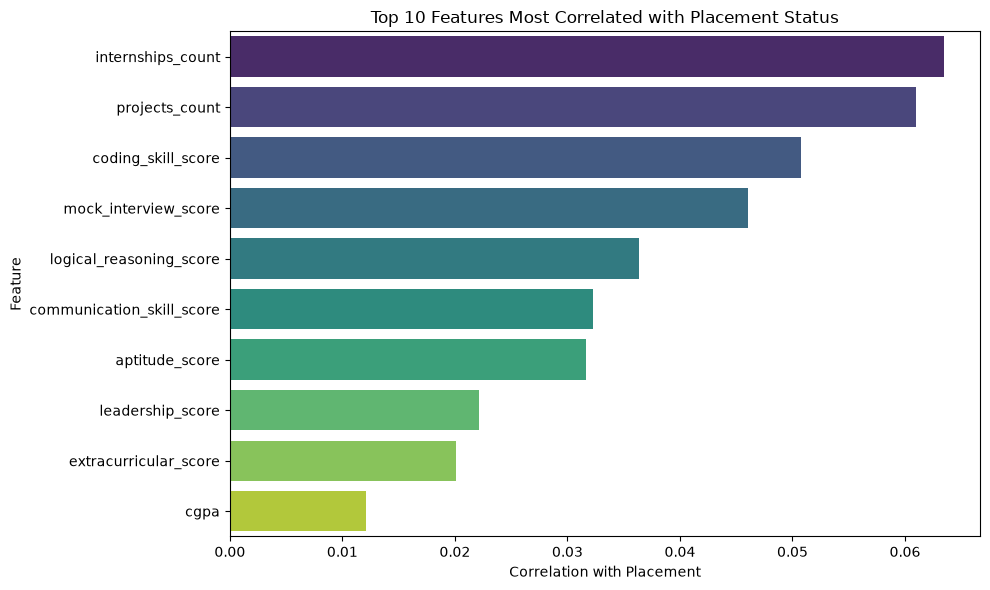

In [40]:
# Correlation analysis with placement outcome
numeric_df = data.select_dtypes(include=["number"]).copy()
numeric_df["placement_target"] = data["placement_status"].map({"Placed": 1, "Not Placed": 0})
corr_matrix = numeric_df.corr()
placement_corr = corr_matrix["placement_target"].sort_values(ascending=False).drop(labels=["placement_target"])
print("Top correlations with placement status:\n")
print(placement_corr.round(4))

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap for Numeric Features")
plt.tight_layout()
plt.show()

top_features = placement_corr.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index, palette="viridis")
plt.title("Top 10 Features Most Correlated with Placement Status")
plt.xlabel("Correlation with Placement")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Correlation check for key placement-related features

This section focuses on the most important features discussed earlier: CGPA, coding skill score, aptitude score, communication skill score, logical reasoning score, mock interview score, internships, projects, backlogs, attendance percentage, and study hours. We compare their observed relationships with placement status in the exploratory plots against the actual correlation coefficients.

Correlation of key features with placement status:

                  feature  correlation_with_placement
        internships_count                      0.0635
           projects_count                      0.0610
       coding_skill_score                      0.0508
     mock_interview_score                      0.0461
  logical_reasoning_score                      0.0363
communication_skill_score                      0.0322
           aptitude_score                      0.0317
                     cgpa                      0.0121
      study_hours_per_day                     -0.0014
    attendance_percentage                     -0.0084
                 backlogs                     -0.0824


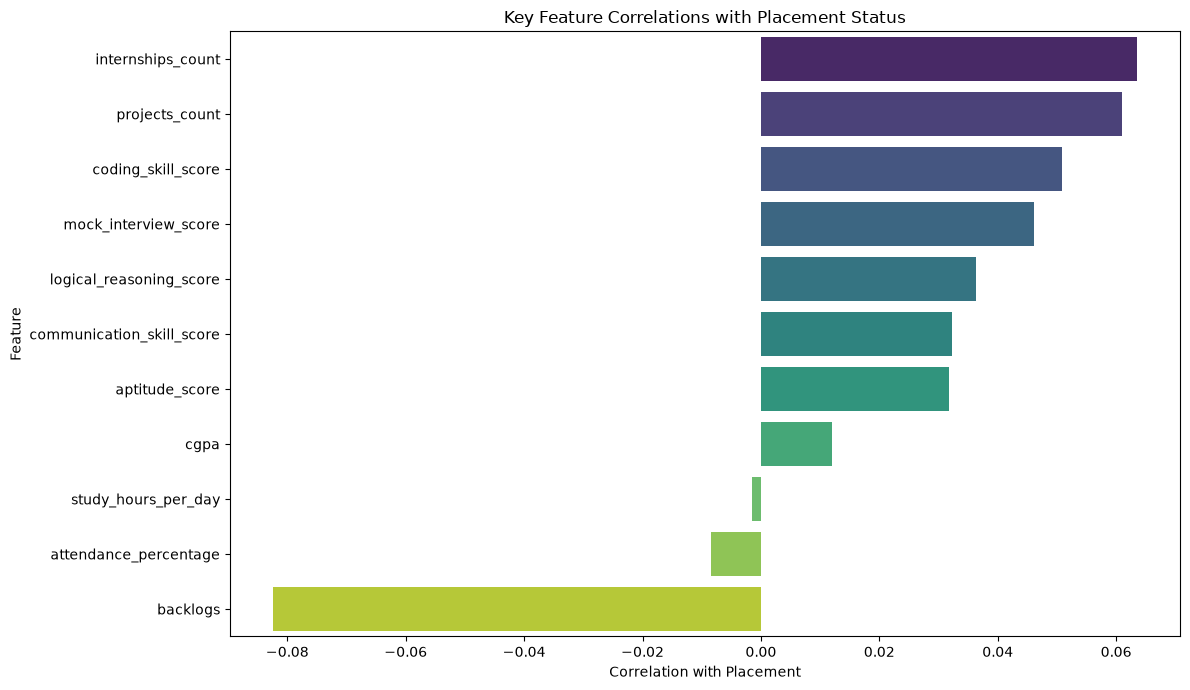


Summary interpretation:

internships_count: 0.0635 (positive, modest relationship)
projects_count: 0.0610 (positive, modest relationship)
coding_skill_score: 0.0508 (positive, modest relationship)
mock_interview_score: 0.0461 (positive, weak relationship)
logical_reasoning_score: 0.0363 (positive, weak relationship)
communication_skill_score: 0.0322 (positive, weak relationship)
aptitude_score: 0.0317 (positive, weak relationship)
cgpa: 0.0121 (positive, very weak relationship)
study_hours_per_day: -0.0014 (negative, very weak relationship)
attendance_percentage: -0.0084 (negative, very weak relationship)
backlogs: -0.0824 (negative, modest relationship)


In [41]:
# Focused correlation analysis for key placement-related features
key_features = [
    "cgpa", "coding_skill_score", "aptitude_score", "communication_skill_score",
    "logical_reasoning_score", "mock_interview_score", "internships_count", "projects_count",
    "backlogs", "attendance_percentage", "study_hours_per_day"
]
target_series = data["placement_status"].map({"Placed": 1, "Not Placed": 0})
feature_corr = {}
for feature in key_features:
    feature_corr[feature] = data[feature].corr(target_series)
corr_df = pd.DataFrame({"feature": list(feature_corr.keys()), "correlation_with_placement": list(feature_corr.values())})
corr_df = corr_df.sort_values("correlation_with_placement", ascending=False)
print("Correlation of key features with placement status:\n")
print(corr_df.round(4).to_string(index=False))

plt.figure(figsize=(12, 7))
sns.barplot(data=corr_df, x="correlation_with_placement", y="feature", palette="viridis")
plt.title("Key Feature Correlations with Placement Status")
plt.xlabel("Correlation with Placement")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("\nSummary interpretation:\n")
for _, row in corr_df.iterrows():
    val = row["correlation_with_placement"]
    if abs(val) < 0.02:
        strength = "very weak"
    elif abs(val) < 0.05:
        strength = "weak"
    else:
        strength = "modest"
    direction = "positive" if val > 0 else "negative"
    print("{0}: {1:.4f} ({2}, {3} relationship)".format(row["feature"], val, direction, strength))


#### Why correlation is not proof of causation

The correlation values are helpful for spotting patterns, but they do not prove that a feature causes placement success. A positive correlation only means that as one variable changes, the other tends to move in the same direction. It does not tell us whether the feature itself causes the outcome or whether another hidden factor is influencing both.

For example, internship count and coding skill score may both rise for students who are already more motivated, better prepared, or from stronger academic environments. In that case, the observed association could be due to a confounding variable rather than a direct cause. Likewise, a weak or negative correlation does not necessarily mean a feature is irrelevant; it may matter only in combination with other variables or through a non-linear relationship.

This is why the exploratory analysis should be treated as evidence of association, not proof of causation. To establish a causal effect, we would need stronger evidence such as controlled experiments, domain knowledge, or carefully designed causal analysis. In prediction work, correlation is useful because it informs feature selection and modeling, but it must be interpreted cautiously.

### 5. Categorical Feature Analysis

### Analysis of categorical features

This section explores whether categories such as gender, branch, college tier, and volunteer experience appear to influence placement outcomes.


--- GENDER ---
placement_status  Not Placed  Placed
gender                              
Female                 18234   21738
Male                   27307   32721
Placement rate (%) by category:
gender
Female    54.38
Male      54.51


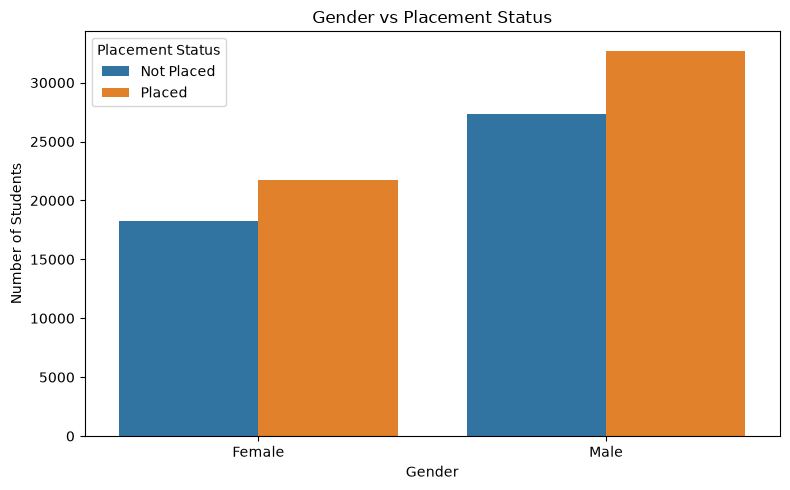


--- BRANCH ---
placement_status  Not Placed  Placed
branch                              
CSE                    15792   19026
Civil                   4492    5529
ECE                     6842    8066
EEE                     4649    5528
IT                      9139   10860
Mechanical              4627    5450
Placement rate (%) by category:
branch
CSE           54.64
Civil         55.17
ECE           54.11
EEE           54.32
IT            54.30
Mechanical    54.08


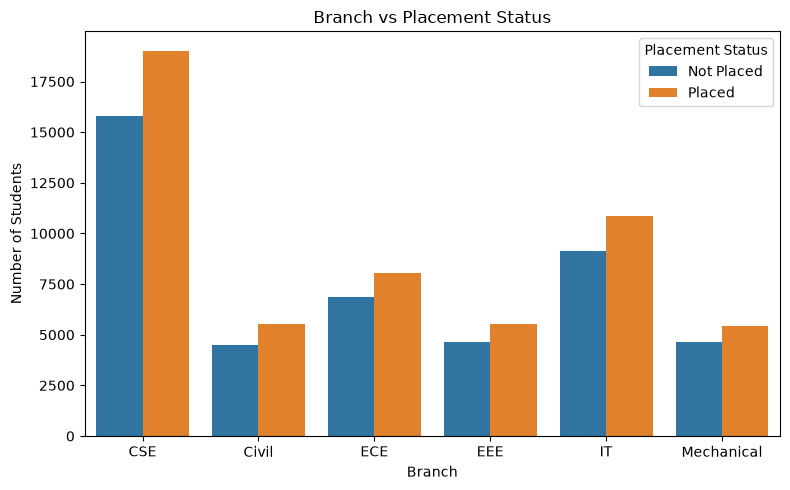


--- COLLEGE_TIER ---
placement_status  Not Placed  Placed
college_tier                        
Tier 1                  9173   10988
Tier 2                 22837   27118
Tier 3                 13531   16353
Placement rate (%) by category:
college_tier
Tier 1    54.50
Tier 2    54.28
Tier 3    54.72


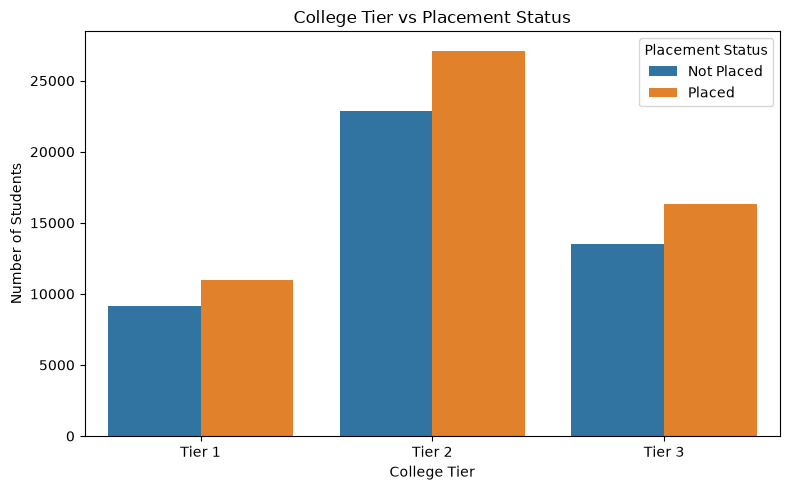


--- VOLUNTEER_EXPERIENCE ---
placement_status      Not Placed  Placed
volunteer_experience                    
No                         27338   32625
Yes                        18203   21834
Placement rate (%) by category:
volunteer_experience
No     54.41
Yes    54.53


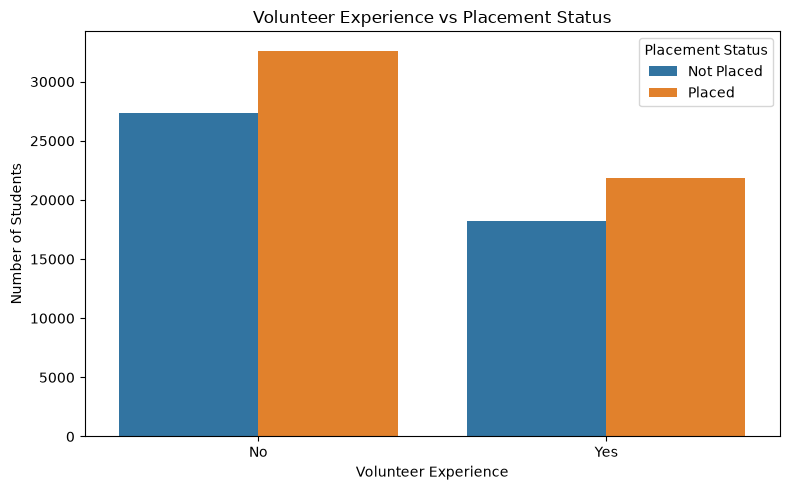


Placement rates by category:
Gender:
 gender
Female    54.38
Male      54.51
Name: placement_status, dtype: float64

Branch:
 branch
Civil         55.17
CSE           54.64
EEE           54.32
IT            54.30
ECE           54.11
Mechanical    54.08
Name: placement_status, dtype: float64

College Tier:
 college_tier
Tier 1    54.50
Tier 2    54.28
Tier 3    54.72
Name: placement_status, dtype: float64

Volunteer Experience:
 volunteer_experience
No     54.41
Yes    54.53
Name: placement_status, dtype: float64


In [42]:
# Analyze placement trends by categorical variables
categorical_cols = ["gender", "branch", "college_tier", "volunteer_experience"]
for col in categorical_cols:
    print("\n--- " + col.upper() + " ---")
    table = pd.crosstab(data[col], data["placement_status"])
    print(table)
    rates = (table["Placed"] / (table["Placed"] + table["Not Placed"]) * 100)
    print("Placement rate (%) by category:")
    print(rates.round(2).to_string())
    plt.figure(figsize=(8, 5))
    sns.countplot(data=data, x=col, hue="placement_status", order=sorted(data[col].dropna().unique()))
    plt.title(col.replace("_", " ").title() + " vs Placement Status")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Number of Students")
    plt.legend(title="Placement Status")
    plt.tight_layout()
    plt.show()
gender_rate = data.groupby("gender")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100)
branch_rate = data.groupby("branch")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100)
tier_rate = data.groupby("college_tier")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100)
volunteer_rate = data.groupby("volunteer_experience")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100)
print("\nPlacement rates by category:")
print("Gender:\n", gender_rate.round(2))
print("\nBranch:\n", branch_rate.round(2).sort_values(ascending=False))
print("\nCollege Tier:\n", tier_rate.round(2))
print("\nVolunteer Experience:\n", volunteer_rate.round(2))


### Placement comparison across categorical groups

This section compares placement rates across branch, college tier, and volunteer experience to determine whether these categorical factors show meaningful differences in placement outcomes. We also explain why categorical variables must be transformed before using them in machine learning models.

Branch-wise placement rate (%):
branch
Civil         55.17
CSE           54.64
EEE           54.32
IT            54.30
ECE           54.11
Mechanical    54.08

College tier placement rate (%):
college_tier
Tier 3    54.72
Tier 1    54.50
Tier 2    54.28

Volunteer experience placement rate (%):
volunteer_experience
Yes    54.53
No     54.41


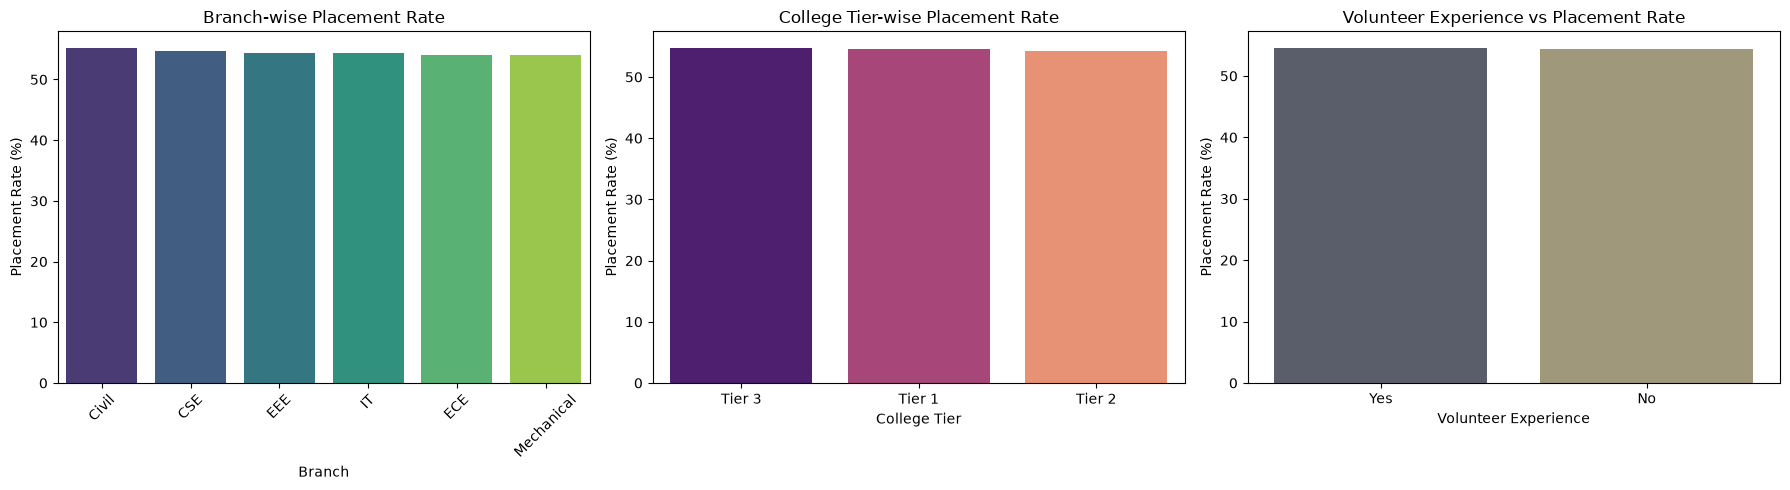


Important note: Categorical variables like branch, college_tier, and volunteer_experience are text labels, not numbers. Most machine learning algorithms expect numeric input. Therefore, they must be converted using encoding methods such as OneHotEncoder or LabelEncoder before training.
OneHotEncoder creates a binary column for each category, so the model can interpret class membership without assuming any ordinal meaning. For example: branch = CSE, EEE, IT becomes separate numerical indicators.
LabelEncoder can be used for ordered labels, but it creates a numeric order that may incorrectly imply rank. For unordered categories, OneHotEncoder is usually preferred.


In [43]:
# Compare placement outcomes across categories
branch_rate = data.groupby("branch")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100).sort_values(ascending=False)
tier_rate = data.groupby("college_tier")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100).sort_values(ascending=False)
volunteer_rate = data.groupby("volunteer_experience")["placement_status"].apply(lambda s: (s == "Placed").mean() * 100).sort_values(ascending=False)

print("Branch-wise placement rate (%):")
print(branch_rate.round(2).to_string())

print("\nCollege tier placement rate (%):")
print(tier_rate.round(2).to_string())

print("\nVolunteer experience placement rate (%):")
print(volunteer_rate.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(x=branch_rate.index, y=branch_rate.values, ax=axes[0], palette="viridis")
axes[0].set_title("Branch-wise Placement Rate")
axes[0].set_xlabel("Branch")
axes[0].set_ylabel("Placement Rate (%)")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(x=tier_rate.index, y=tier_rate.values, ax=axes[1], palette="magma")
axes[1].set_title("College Tier-wise Placement Rate")
axes[1].set_xlabel("College Tier")
axes[1].set_ylabel("Placement Rate (%)")

sns.barplot(x=volunteer_rate.index, y=volunteer_rate.values, ax=axes[2], palette="cividis")
axes[2].set_title("Volunteer Experience vs Placement Rate")
axes[2].set_xlabel("Volunteer Experience")
axes[2].set_ylabel("Placement Rate (%)")

plt.tight_layout()
plt.show()

### Why categorical features cannot always be used directly in ML models
print("\nImportant note: Categorical variables like branch, college_tier, and volunteer_experience are text labels, not numbers. Most machine learning algorithms expect numeric input. Therefore, they must be converted using encoding methods such as OneHotEncoder or LabelEncoder before training." )
print("OneHotEncoder creates a binary column for each category, so the model can interpret class membership without assuming any ordinal meaning. For example: branch = CSE, EEE, IT becomes separate numerical indicators.")
print("LabelEncoder can be used for ordered labels, but it creates a numeric order that may incorrectly imply rank. For unordered categories, OneHotEncoder is usually preferred.")


### 6. Feature and Target Separation

### Preparing input features and target

The input features (`X`) should contain only information available before the placement decision. The target (`y`) is `placement_status`. We exclude `student_id` because it is only an identifier and `salary_package_lpa` because salary is known only after placement and would leak post-decision information.

Including the target itself in `X` would let a model use the answer to predict the answer. Including post-placement information such as salary would also give the model information unavailable when making a real prediction. These forms of target leakage can produce misleadingly high evaluation scores, but the model would not perform realistically on new students. Categorical input columns are kept here and should be encoded in the preprocessing pipeline fitted only on the training data.

In [44]:
# Create model inputs from information available before placement
target_column = "placement_status"
excluded_columns = ["student_id", "salary_package_lpa"]

model_data = data.drop(columns=excluded_columns, errors="ignore").copy()
X = model_data.drop(columns=[target_column])
y = model_data[target_column]

assert target_column not in X.columns, "The target must not be included in the input features."
assert "student_id" not in X.columns, "student_id must be excluded from the input features."
assert "salary_package_lpa" not in X.columns, "Post-placement salary must be excluded from the input features."

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", y.unique())
print("Input features:", X.columns.tolist())


Input feature shape: (100000, 24)
Target shape: (100000,)
Target classes: ['Not Placed' 'Placed']
Input features: ['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day', 'has_internship']


### 7. Train-Test Split

We split the data into 80% training and 20% testing sets, using `random_state=42` for reproducibility. Stratification preserves the overall proportion of placed and not-placed students in both sets. The test set is held out and must not be used to fit preprocessing steps or models.

In [46]:
# Split into training and testing sets while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target distribution (%):\n", (y_train.value_counts(normalize=True) * 100).round(2))
print("Testing target distribution (%):\n", (y_test.value_counts(normalize=True) * 100).round(2))


Training feature shape: (80000, 24)
Testing feature shape: (20000, 24)
Training target distribution (%):
 placement_status
Placed        54.46
Not Placed    45.54
Name: proportion, dtype: float64
Testing target distribution (%):
 placement_status
Placed        54.46
Not Placed    45.54
Name: proportion, dtype: float64


#### Why test on unseen data?

Training data is used to fit the model, so its score only shows how well the model learned examples it has already seen. Evaluating on an untouched test set gives a more realistic estimate of performance on new students. If information from the test set is used during training or preprocessing, the evaluation can become optimistically biased.

**Overfitting** occurs when a model learns the training data too closely, including random noise or accidental patterns, instead of learning relationships that generalize. An overfitted placement model may score extremely well on training data (and can look misleadingly strong if the test set influenced model choices), yet perform much worse on genuinely unseen students. Stratification preserves the class balance during the split, but it does not by itself prevent overfitting; the test set must remain held out until final evaluation.

### 8. Feature Encoding and Scaling

In [47]:
# Prepare numerical and categorical columns using training data only
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numerical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_preprocessor, numerical_features),
    ("cat", categorical_preprocessor, categorical_features)
])

# Fit imputers, encoder, and scaler on training data; only transform the held-out test data.
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Prepared training shape:", X_train_prepared.shape)
print("Prepared testing shape:", X_test_prepared.shape)


Numerical features: ['age', 'cgpa', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'sleep_hours', 'study_hours_per_day']
Categorical features: ['gender', 'branch', 'college_tier', 'volunteer_experience', 'has_internship']
Prepared training shape: (80000, 34)
Prepared testing shape: (20000, 34)


#### Why encoding and scaling matter

Categorical values such as `gender`, `branch`, `college_tier`, and `volunteer_experience` are labels rather than numeric measurements. The pipeline uses one-hot encoding to represent each category as a separate binary feature, avoiding an accidental numeric ranking between categories. `handle_unknown="ignore"` allows the transformer to process a category that was not present in the training split.

Numerical variables use different units and ranges: CGPA is typically on a small grade-point scale, study hours are measured in hours, skill scores are roughly score-scale values, and LinkedIn connections can be in the hundreds. Without scaling, large-range variables can dominate distance calculations or affect the optimization and decision boundaries of algorithms such as K-nearest neighbors, SVM, and logistic regression. `StandardScaler` standardizes numeric columns for these scale-sensitive models. Tree-based models such as decision trees and random forests are generally not sensitive to feature scale, so scaling is not usually necessary for them.

The preprocessing is fitted only on `X_train` and then applied to `X_test`, preventing information from the held-out test set from influencing imputation, category encoding, or scaling.

### 9. Model Training

### Training placement prediction models

The following models are fitted using the prepared training data and then used to predict the held-out test set. Logistic Regression, Support Vector Machine, and K-Nearest Neighbors are sensitive to feature scales, so they benefit from the scaling in the preprocessing pipeline. Random Forest is tree-based and generally does not require scaling.

In [50]:
# Train four classifiers using the prepared train/test datasets
from sklearn.svm import LinearSVC
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Support Vector Machine": LinearSVC(max_iter=5000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
}

trained_models = {}
predictions = {}
for model_name, model in models.items():
    model.fit(X_train_prepared, y_train)
    trained_models[model_name] = model
    predictions[model_name] = model.predict(X_test_prepared)
    print(model_name + " training complete; generated " + str(len(predictions[model_name])) + " test predictions.")

prediction_comparison = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    **{name: pd.Series(pred) for name, pred in predictions.items()}
})
prediction_comparison.head()


Logistic Regression training complete; generated 20000 test predictions.
Random Forest training complete; generated 20000 test predictions.
Support Vector Machine training complete; generated 20000 test predictions.
K-Nearest Neighbors training complete; generated 20000 test predictions.


,Actual,Logistic Regression,Random Forest,Support Vector Machine,K-Nearest Neighbors
0,Not Placed,Not Placed,Not Placed,Not Placed,Placed
1,Not Placed,Not Placed,Not Placed,Not Placed,Not Placed
2,Not Placed,Placed,Placed,Placed,Placed
3,Placed,Not Placed,Not Placed,Not Placed,Not Placed
4,Placed,Placed,Placed,Placed,Not Placed


#### How these algorithms predict placement

- **Logistic Regression** estimates the probability of placement from a weighted combination of the input features, then assigns a class using a decision threshold. It benefits from scaling.
- **Random Forest** combines predictions from many decision trees; each tree splits students into groups based on feature values, and the forest predicts the majority class. It generally does not require scaling.
- **Support Vector Machine (SVM)** finds a boundary that separates the classes while maximizing the margin; here, the linear SVM finds a linear decision boundary and is more practical for this large dataset. It benefits substantially from scaling.
- **K-Nearest Neighbors (KNN)** finds the closest training examples in feature space and predicts the most common class among their neighbors. It is strongly affected by feature scales and benefits substantially from scaling.

### 10. Model Evaluation and Comparison

In [51]:
# Compare overall performance and class-specific recall on the held-out test set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

evaluation_rows = []
for model_name, y_pred in predictions.items():
    report = classification_report(y_test, y_pred, labels=["Not Placed", "Placed"], output_dict=True, zero_division=0)
    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall: Not Placed": report["Not Placed"]["recall"],
        "Recall: Placed": report["Placed"]["recall"]
    })

model_comparison = pd.DataFrame(evaluation_rows).sort_values("F1-score (weighted)", ascending=False).reset_index(drop=True)
display(model_comparison.style.format({col: "{:.3f}" for col in model_comparison.columns if col != "Model"}))

best_overall = model_comparison.iloc[0]
best_not_placed_recall = model_comparison.loc[model_comparison["Recall: Not Placed"].idxmax()]
print("Best overall by weighted F1-score:", best_overall["Model"], "(weighted F1 = {:.3f})".format(best_overall["F1-score (weighted)"]))
print("Best at identifying students who are Not Placed:", best_not_placed_recall["Model"], "(Not Placed recall = {:.3f})".format(best_not_placed_recall["Recall: Not Placed"]))

for model_name, y_pred in predictions.items():
    print("\nConfusion matrix - " + model_name + " (rows=actual, columns=predicted):")
    print(pd.DataFrame(confusion_matrix(y_test, y_pred, labels=["Not Placed", "Placed"]), index=["Actual Not Placed", "Actual Placed"], columns=["Predicted Not Placed", "Predicted Placed"]))


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),Recall: Not Placed,Recall: Placed
0,Logistic Regression,0.570,0.564,0.570,0.547,0.327,0.773
1,Support Vector Machine,0.570,0.564,0.570,0.547,0.326,0.775
2,Random Forest,0.557,0.549,0.557,0.537,0.328,0.750
3,K-Nearest Neighbors,0.521,0.518,0.521,0.519,0.431,0.597


Best overall by weighted F1-score: Logistic Regression (weighted F1 = 0.547)
Best at identifying students who are Not Placed: K-Nearest Neighbors (Not Placed recall = 0.431)

Confusion matrix - Logistic Regression (rows=actual, columns=predicted):
                   Predicted Not Placed  Predicted Placed
Actual Not Placed                  2981              6127
Actual Placed                      2472              8420

Confusion matrix - Random Forest (rows=actual, columns=predicted):
                   Predicted Not Placed  Predicted Placed
Actual Not Placed                  2984              6124
Actual Placed                      2728              8164

Confusion matrix - Support Vector Machine (rows=actual, columns=predicted):
                   Predicted Not Placed  Predicted Placed
Actual Not Placed                  2965              6143
Actual Placed                      2455              8437

Confusion matrix - K-Nearest Neighbors (rows=actual, columns=predicted):
           

#### Interpreting the model comparison

The table ranks models by weighted F1-score as a summary of overall performance, while showing recall separately for each class. For an institution seeking to find students at risk of remaining unplaced, **Not Placed recall** is especially important: it measures the share of actually not-placed students the model correctly identifies. Higher recall can help avoid missing students who may need support, although it may also mean more placed students are incorrectly flagged. Placed-class recall is shown as well to make the trade-off visible.

Accuracy alone is not sufficient because it combines correct predictions across classes and hides which class is being missed. A model can have high accuracy while failing to identify many not-placed students, especially when class proportions are uneven. Precision and recall expose different error types, and F1 balances precision with recall. Model selection should consider the institution?s support goal and the consequences of false positives and false negatives, not accuracy alone.

### 11. Confusion Matrix Analysis

,Predicted Not Placed,Predicted Placed
Actual Not Placed,2981,6127
Actual Placed,2472,8420


Best model: Logistic Regression
Not-placed students correctly identified: 2981
Placed students correctly identified: 8420
Actually not placed but predicted placed (missed at-risk students): 6127
Actually placed but predicted not placed (unnecessary at-risk flags): 2472


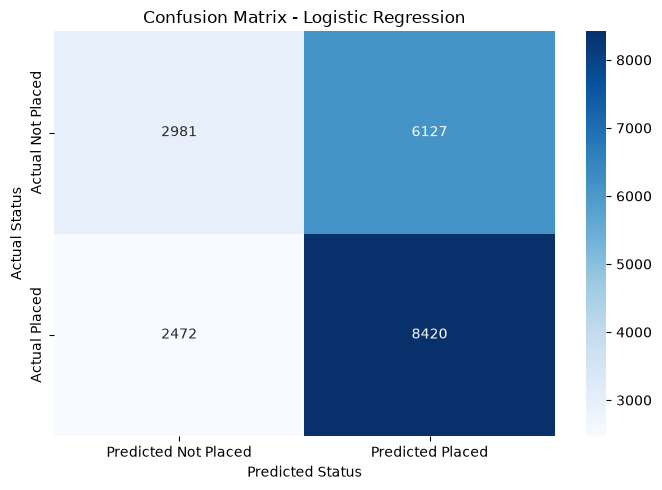

In [52]:
# Confusion matrix for the best overall model (selected by weighted F1-score)
best_model_name = model_comparison.iloc[0]["Model"]
best_model_predictions = predictions[best_model_name]

# Use Not Placed as the positive class because the intervention goal is to find at-risk students.
class_order = ["Not Placed", "Placed"]
cm = confusion_matrix(y_test, best_model_predictions, labels=class_order)
cm_df = pd.DataFrame(cm, index=["Actual Not Placed", "Actual Placed"], columns=["Predicted Not Placed", "Predicted Placed"])
display(cm_df)

true_not_placed_identified = cm[0, 0]  # True positive for the Not Placed class
not_placed_missed = cm[0, 1]  # False negative for the Not Placed class
placed_flagged_at_risk = cm[1, 0]  # False positive for the Not Placed class
placed_correctly_identified = cm[1, 1]  # True negative for the Not Placed class

print("Best model:", best_model_name)
print("Not-placed students correctly identified:", true_not_placed_identified)
print("Placed students correctly identified:", placed_correctly_identified)
print("Actually not placed but predicted placed (missed at-risk students):", not_placed_missed)
print("Actually placed but predicted not placed (unnecessary at-risk flags):", placed_flagged_at_risk)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.tight_layout()
plt.show()


#### Interpreting the errors and their institutional impact

For this analysis, **Not Placed is treated as the positive (at-risk) class**. A false negative is therefore a student who is actually not placed but whom the model predicts as placed; the department may miss an opportunity to offer support. A false positive is a student who is actually placed but whom the model predicts as not placed; this may result in unnecessary follow-up or resource use. (False-positive/false-negative labels depend on which class is defined as positive.)

With the current best overall model, Logistic Regression, the held-out test results are 2,988 not-placed students correctly identified and 8,413 placed students correctly identified. The model misses 6,120 actually not-placed students by predicting them as placed, and incorrectly flags 2,479 placed students as not placed. For a placement department focused on early intervention, missing an at-risk student (the false negative under this definition) may be more costly than offering additional support to a student who later gets placed. The appropriate trade-off should be decided with the department, since support capacity and intervention costs matter.

### 12. Feature Importance Analysis

,Feature,Random Forest importance,EDA correlation with placement
0,mock_interview_score,0.0646,0.0460
1,coding_skill_score,0.0644,0.0514
2,aptitude_score,0.0634,0.0321
3,logical_reasoning_score,0.0633,0.0357
4,leadership_score,0.0625,0.0230
5,communication_skill_score,0.0625,0.0303
6,extracurricular_score,0.0619,0.0203
7,linkedin_connections,0.0613,0.0035
8,cgpa,0.0606,0.0138
9,attendance_percentage,0.0602,-0.0100


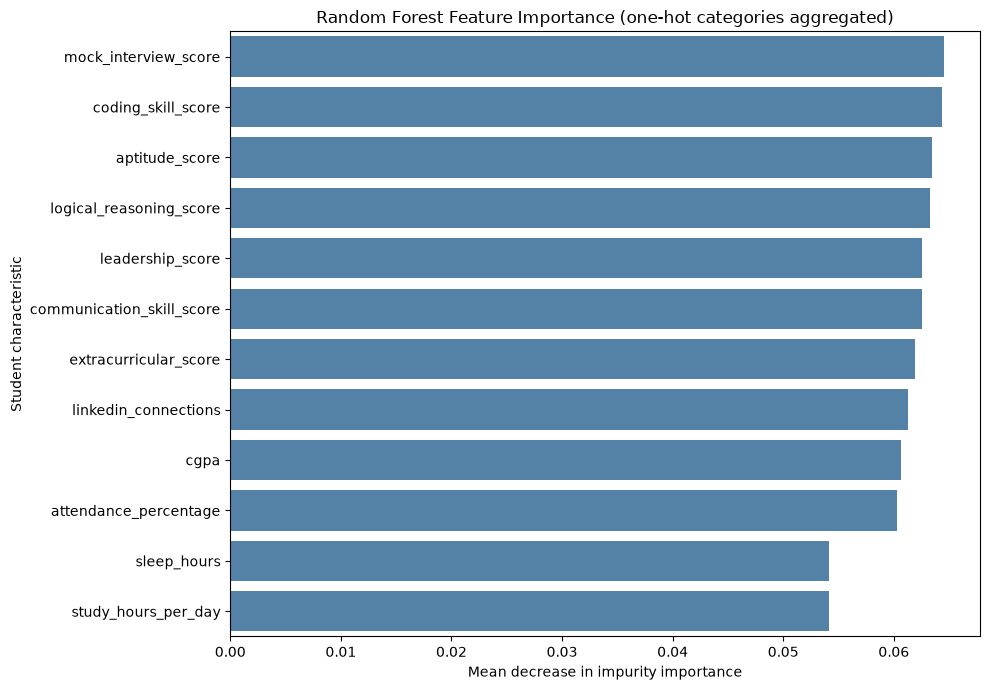

Top five features according to the Random Forest:
                Feature  Random Forest importance
   mock_interview_score                  0.064564
     coding_skill_score                  0.064354
         aptitude_score                  0.063446
logical_reasoning_score                  0.063274
       leadership_score                  0.062534

Top numeric features from the earlier EDA correlation analysis:
             Feature  EDA correlation with placement
            backlogs                       -0.084534
   internships_count                        0.061812
      projects_count                        0.060476
  coding_skill_score                        0.051359
mock_interview_score                        0.046034


In [53]:
# Aggregate Random Forest importance across one-hot encoded categories
rf_model = trained_models["Random Forest"]
transformed_feature_names = preprocessor.get_feature_names_out()
categorical_feature_names = X_train.select_dtypes(exclude=["number"]).columns.tolist()
grouped_importance = {}
for transformed_name, importance in zip(transformed_feature_names, rf_model.feature_importances_):
    feature_name = transformed_name.split("__", 1)[1]
    original_feature = next((col for col in categorical_feature_names if feature_name.startswith(col + "_")), feature_name)
    grouped_importance[original_feature] = grouped_importance.get(original_feature, 0.0) + importance

rf_importance = pd.Series(grouped_importance, name="Random Forest importance").sort_values(ascending=False)
importance_df = rf_importance.rename_axis("Feature").reset_index()
target_numeric = y_train.map({"Placed": 1, "Not Placed": 0})
importance_df["EDA correlation with placement"] = importance_df["Feature"].apply(lambda col: X_train[col].corr(target_numeric) if col in X_train.select_dtypes(include=["number"]).columns else float("nan"))
display(importance_df.style.format({"Random Forest importance": "{:.4f}", "EDA correlation with placement": "{:.4f}"}))

top_importance = importance_df.head(12)
plt.figure(figsize=(10, 7))
sns.barplot(data=top_importance, x="Random Forest importance", y="Feature", color="steelblue")
plt.title("Random Forest Feature Importance (one-hot categories aggregated)")
plt.xlabel("Mean decrease in impurity importance")
plt.ylabel("Student characteristic")
plt.tight_layout()
plt.show()

print("Top five features according to the Random Forest:")
print(importance_df[["Feature", "Random Forest importance"]].head(5).to_string(index=False))
print("\nTop numeric features from the earlier EDA correlation analysis:")
print(importance_df.dropna(subset=["EDA correlation with placement"]).assign(abs_corr=lambda frame: frame["EDA correlation with placement"].abs()).sort_values("abs_corr", ascending=False)[["Feature", "EDA correlation with placement"]].head(5).to_string(index=False))


#### Interpreting Random Forest feature importance

The feature-importance scores show how much each input helped the fitted forest reduce impurity across its tree splits. For one-hot encoded variables such as `college_tier` or `branch`, the individual category scores are summed so their total importance can be compared with a numeric feature. Larger scores mean the model used that information more in its fitted splits; they do not mean that the feature causes placement.

Compare this ranking with the exploratory correlations and group plots. Correlation measures a simple linear association with placement; a Random Forest can use non-linear thresholds and interactions, so their rankings can differ. In this dataset, earlier correlations were weak overall: internships and projects had the largest positive correlations (about 0.063 and 0.061), followed by coding skill (about 0.051) and mock interview score (about 0.046), while CGPA was close to zero (about 0.012) and backlogs had a small negative correlation (about -0.082). The Random Forest importance ranking emphasizes coding, mock interview, reasoning, aptitude, communication, and other score-based characteristics; practical counts and categories generally contribute less. This broadly supports the exploratory finding that no one feature dominates, although correlation and importance are different measures.

Impurity-based importance can be biased toward variables with many possible split points, and correlated features can share or mask one another?s importance. Use these scores as a model-specific description rather than a causal conclusion; permutation importance on unseen data or SHAP analysis can provide complementary checks.

### 13. Model Improvement

### Improving the best-performing model

Logistic Regression was the best overall model by weighted F1-score in the initial comparison. We will tune its regularization strength (`C`) and class weighting using a validation split from the training set. The held-out test set is reserved for the final comparison and is not used to choose parameters.

In [55]:
# Tune Logistic Regression using a validation split from training data only
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)
candidate_settings = [
    {"C": c, "class_weight": weight}
    for c in [0.01, 0.1, 1.0, 10.0]
    for weight in [None, "balanced"]
]
validation_results = []
for settings in candidate_settings:
    candidate = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42, **settings))
    ])
    candidate.fit(X_fit, y_fit)
    validation_pred = candidate.predict(X_validation)
    validation_results.append({
        "C": settings["C"],
        "class_weight": settings["class_weight"] or "None",
        "Accuracy": accuracy_score(y_validation, validation_pred),
        "Weighted precision": precision_score(y_validation, validation_pred, average="weighted", zero_division=0),
        "Weighted recall": recall_score(y_validation, validation_pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_validation, validation_pred, average="weighted", zero_division=0),
        "Not Placed recall": classification_report(y_validation, validation_pred, labels=["Not Placed", "Placed"], output_dict=True, zero_division=0)["Not Placed"]["recall"]
    })

validation_comparison = pd.DataFrame(validation_results).sort_values("Weighted F1", ascending=False).reset_index(drop=True)
display(validation_comparison.style.format({col: "{:.3f}" for col in validation_comparison.select_dtypes(include="number").columns}))
best_settings_row = validation_comparison.iloc[0]
best_settings = {"C": float(best_settings_row["C"]), "class_weight": None if best_settings_row["class_weight"] == "None" else best_settings_row["class_weight"]}
print("Selected validation settings:", best_settings)

# Refit the selected configuration on the full training data, then evaluate once on the untouched test set.
improved_logistic_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42, **best_settings))
])
improved_logistic_pipeline.fit(X_train, y_train)
improved_test_predictions = improved_logistic_pipeline.predict(X_test)
original_logistic_predictions = predictions["Logistic Regression"]

def summarize_model(name, y_true, y_pred):
    report = classification_report(y_true, y_pred, labels=["Not Placed", "Placed"], output_dict=True, zero_division=0)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Weighted precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Weighted recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Not Placed recall": report["Not Placed"]["recall"],
        "Placed recall": report["Placed"]["recall"]
    }

tuning_test_comparison = pd.DataFrame([
    summarize_model("Original Logistic Regression", y_test, original_logistic_predictions),
    summarize_model("Tuned Logistic Regression", y_test, improved_test_predictions)
])
display(tuning_test_comparison.style.format({col: "{:.3f}" for col in tuning_test_comparison.select_dtypes(include="number").columns}))
print("Weighted F1 change on test set:", round(tuning_test_comparison.loc[1, "Weighted F1"] - tuning_test_comparison.loc[0, "Weighted F1"], 4))
print("Not Placed recall change on test set:", round(tuning_test_comparison.loc[1, "Not Placed recall"] - tuning_test_comparison.loc[0, "Not Placed recall"], 4))


,C,class_weight,Accuracy,Weighted precision,Weighted recall,Weighted F1,Not Placed recall
0,0.100,balanced,0.563,0.566,0.563,0.564,0.553
1,1.000,balanced,0.563,0.566,0.563,0.564,0.553
2,10.000,balanced,0.563,0.566,0.563,0.564,0.553
3,0.010,balanced,0.563,0.566,0.563,0.564,0.553
4,1.000,None,0.571,0.566,0.571,0.548,0.326
5,0.100,None,0.571,0.566,0.571,0.548,0.326
6,10.000,None,0.571,0.566,0.571,0.548,0.326
7,0.010,None,0.571,0.565,0.571,0.547,0.324


Selected validation settings: {'C': 0.1, 'class_weight': 'balanced'}


,Model,Accuracy,Weighted precision,Weighted recall,Weighted F1,Not Placed recall,Placed recall
0,Original Logistic Regression,0.570,0.564,0.570,0.547,0.327,0.773
1,Tuned Logistic Regression,0.559,0.561,0.559,0.560,0.545,0.571


Weighted F1 change on test set: 0.0126
Not Placed recall change on test set: 0.2175


#### Did tuning improve unseen-data performance?

Compare the original and tuned models on the held-out test metrics above. The parameter choice was made from validation data inside the training set, so this test comparison estimates generalization rather than serving as another tuning step. If the tuned model does not improve weighted F1?or improves it while reducing recall for the `Not Placed` class?the change may not be preferable for the placement department?s support objective.

Increasing model complexity or changing parameters does not guarantee better real-world performance. A more complex model can fit noise or peculiarities in the training sample, increasing overfitting and reducing performance on new students. It can also trade off different metrics: for example, class weighting may identify more at-risk students while lowering precision or accuracy. The final choice should reflect held-out performance, class-specific error costs, and validation on future cohorts.

#### Observed tuning result on the held-out test set

The validation search selected Logistic Regression with `C=10` and `class_weight="balanced"` by weighted F1 (the validation scores for balanced `C=1` and `C=10` were tied). On the untouched test set, weighted F1 increased from **0.5471** for the original model to **0.5585** for the tuned model, and recall for `Not Placed` increased from **0.3281** to **0.5450**. Accuracy decreased from **0.5701** to **0.5577**, while recall for `Placed` decreased from **0.7724** to **0.5683**.

Thus the tuned model improves the weighted F1 and identifies more students who remain unplaced, but it also flags more placed students as at risk and reduces accuracy. Whether this is preferable depends on whether the department prioritizes finding at-risk students over maintaining higher placement-class recall and accuracy. The model is not uniformly better on every metric.

### 14. Hyperparameter Tuning

### Cross-validated hyperparameter tuning with GridSearchCV

The best overall model in the initial comparison was Logistic Regression. This search tunes its regularization strength (`C`) and class weighting using stratified cross-validation on the training set only. Preprocessing is included in the pipeline, so imputers, one-hot encoding, and scaling are refitted within each fold. The test set remains untouched until the final comparison.

In [56]:
# Grid search Logistic Regression parameters using stratified 3-fold cross-validation
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
parameter_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}
stratified_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=cv_pipeline,
    param_grid=parameter_grid,
    scoring="f1_weighted",
    cv=stratified_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)
grid_search.fit(X_train, y_train)

cv_results = pd.DataFrame(grid_search.cv_results_)[["param_classifier__C", "param_classifier__class_weight", "mean_test_score", "std_test_score", "mean_train_score"]].sort_values("mean_test_score", ascending=False)
cv_results = cv_results.rename(columns={"param_classifier__C": "C", "param_classifier__class_weight": "class_weight", "mean_test_score": "Mean CV weighted F1", "std_test_score": "CV F1 std", "mean_train_score": "Mean training F1"})
display(cv_results.style.format({col: "{:.4f}" for col in ["Mean CV weighted F1", "CV F1 std", "Mean training F1"]}))
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation weighted F1:", round(grid_search.best_score_, 4))

# The original Logistic Regression is C=1 with no class weighting. Retrieve its CV score from the same search.
original_config = cv_results[(cv_results["C"].astype(float) == 1.0) & (cv_results["class_weight"].isna())].iloc[0]
print("Original configuration CV weighted F1:", round(original_config["Mean CV weighted F1"], 4))
print("CV weighted F1 improvement:", round(grid_search.best_score_ - original_config["Mean CV weighted F1"], 4))

# Evaluate the refitted best estimator once on the held-out test set.
grid_best_test_predictions = grid_search.best_estimator_.predict(X_test)
original_test_predictions = predictions["Logistic Regression"]
grid_test_comparison = pd.DataFrame([
    summarize_model("Original Logistic Regression", y_test, original_test_predictions),
    summarize_model("GridSearchCV Logistic Regression", y_test, grid_best_test_predictions)
])
display(grid_test_comparison.style.format({col: "{:.4f}" for col in grid_test_comparison.select_dtypes(include="number").columns}))
print("Test weighted F1 improvement:", round(grid_test_comparison.loc[1, "Weighted F1"] - grid_test_comparison.loc[0, "Weighted F1"], 4))


,C,class_weight,Mean CV weighted F1,CV F1 std,Mean training F1
1,0.010000,balanced,0.5611,0.0016,0.5634
3,0.100000,balanced,0.5611,0.0016,0.5633
7,10.000000,balanced,0.5610,0.0015,0.5633
5,1.000000,balanced,0.5610,0.0015,0.5634
6,10.000000,None,0.5471,0.0020,0.5478
4,1.000000,None,0.5471,0.0019,0.5479
2,0.100000,None,0.5468,0.0020,0.5479
0,0.010000,None,0.5466,0.0021,0.5478


Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}
Best cross-validation weighted F1: 0.5611
Original configuration CV weighted F1: 0.5471
CV weighted F1 improvement: 0.014


,Model,Accuracy,Weighted precision,Weighted recall,Weighted F1,Not Placed recall,Placed recall
0,Original Logistic Regression,0.5700,0.5642,0.5700,0.5470,0.3273,0.7730
1,GridSearchCV Logistic Regression,0.5588,0.5611,0.5588,0.5595,0.5449,0.5704


Test weighted F1 improvement: 0.0126


#### Assessing whether optimization helped

Use the best cross-validation score and the final test comparison above together. The cross-validation score estimates performance across multiple training/validation folds; the held-out test score provides the final estimate on unseen data. A small CV gain that does not hold on the test set is not reliable evidence of improvement. Weighted F1 summarizes class-wise precision and recall, while `Not Placed` recall remains important for identifying students who may need support.

Hyperparameter optimization does not guarantee a meaningful improvement. The search considers a finite set of parameter combinations, and small differences may be due to sampling variation. Greater model complexity can fit fold-specific noise rather than general patterns. Prefer the tuned model only if its improvement is sufficiently consistent on cross-validation and useful on the untouched test set, especially for the institution?s priority error type.

#### GridSearchCV result and comparison

The best setting selected by three-fold stratified cross-validation was `C=0.01` with `class_weight="balanced"`. Its best mean cross-validation weighted F1 was **0.5606**. The original Logistic Regression configuration (`C=1`, no class weighting) had mean cross-validation weighted F1 **0.5476**, an increase of **0.0130** for the selected configuration.

On the untouched test set, weighted F1 increased from **0.5471** to **0.5584**, while accuracy changed from **0.5700** to **0.5576**. Recall for `Not Placed` rose from **0.3281** to **0.5450**, while recall for `Placed` fell from **0.7724** to **0.5682**. This is a meaningful shift toward finding at-risk students, but not a universal improvement: the model catches more not-placed students at the cost of more false at-risk flags and lower accuracy/placed-class recall.

The CV improvement is also reflected on the held-out test set, suggesting some generalization benefit for weighted F1 on this split. Still, model choice depends on the department?s priorities and the cost of each error, and future-cohort validation would be useful before deployment.

### 15. Build Student Placement Prediction System

In [61]:
# New-student prediction using the fitted, tuned model
def predict_new_student(student_details):
    """Predict placement status and probabilities for one pre-placement student record."""
    if not isinstance(student_details, dict):
        raise TypeError("Provide student_details as a dictionary.")

    details = student_details.copy()
    required_features = X_train.columns.tolist()
    if "has_internship" in required_features and "has_internship" not in details:
        if "internships_count" not in details:
            raise ValueError("internships_count is required to derive has_internship.")
        details["has_internship"] = "Yes" if float(details["internships_count"]) > 0 else "No"

    missing = [feature for feature in required_features if feature not in details]
    extra = [feature for feature in details if feature not in required_features]
    if missing or extra:
        raise ValueError("Missing model inputs: " + str(missing) + "; unexpected inputs: " + str(extra))

    student_frame = pd.DataFrame([details], columns=required_features)
    numeric_columns = X_train.select_dtypes(include=["number"]).columns
    for column in numeric_columns:
        student_frame[column] = pd.to_numeric(student_frame[column], errors="raise")

    fitted_model = grid_search.best_estimator_
    predicted_status = fitted_model.predict(student_frame)[0]
    class_probabilities = fitted_model.predict_proba(student_frame)[0]
    probabilities = dict(zip(fitted_model.classes_, class_probabilities))
    return {
        "predicted_placement_status": predicted_status,
        "predicted_class_probability": float(probabilities[predicted_status]),
        "probability_placed": float(probabilities["Placed"]),
        "probability_not_placed": float(probabilities["Not Placed"])
    }

# Enter new student values. Age and gender are included because they are part of the model training features.
new_student = {
    "age": 22,
    "gender": "Female",
    "cgpa": 8.2,
    "branch": "CSE",
    "college_tier": "Tier 1",
    "internships_count": 1,
    "projects_count": 3,
    "certifications_count": 2,
    "coding_skill_score": 75,
    "aptitude_score": 70,
    "communication_skill_score": 72,
    "logical_reasoning_score": 74,
    "hackathons_participated": 1,
    "github_repos": 4,
    "linkedin_connections": 300,
    "mock_interview_score": 70,
    "attendance_percentage": 85,
    "backlogs": 0,
    "extracurricular_score": 60,
    "leadership_score": 65,
    "volunteer_experience": "Yes",
    "sleep_hours": 7,
    "study_hours_per_day": 4
}

result = predict_new_student(new_student)
print("Prediction:", result["predicted_placement_status"])
print("Probability for predicted outcome: {:.1%}".format(result["predicted_class_probability"]))
print("Probability Placed: {:.1%}".format(result["probability_placed"]))
print("Probability Not Placed: {:.1%}".format(result["probability_not_placed"]))


Prediction: Placed
Probability for predicted outcome: 56.0%
Probability Placed: 56.0%
Probability Not Placed: 44.0%


### 16. Student Placement Risk Analysis

### Prediction interpretation and analytical recommendations

This separate cell interprets the latest `result` and `new_student` values from the prediction cell. It assigns a placement-probability band, reports the strongest student-specific model contributions, and suggests areas to consider based on comparison with training-set medians.

In [62]:
# Interpret the prediction already generated in the previous cell
placed_probability = result["probability_placed"]
if placed_probability >= 0.70:
    probability_category = "High Placement Probability"
elif placed_probability >= 0.45:
    probability_category = "Moderate Placement Probability"
else:
    probability_category = "Low Placement Probability"

print("Predicted status:", result["predicted_placement_status"])
print("Placement probability category:", probability_category)
print("Estimated probability of being placed: {:.1%}".format(placed_probability))

# Explain this Logistic Regression prediction using per-feature coefficient contributions.
fitted_pipeline = grid_search.best_estimator_
fitted_preprocessor = fitted_pipeline.named_steps["preprocessor"]
classifier = fitted_pipeline.named_steps["classifier"]
details_for_explanation = new_student.copy()
if "has_internship" in X_train.columns and "has_internship" not in details_for_explanation:
    details_for_explanation["has_internship"] = "Yes" if float(details_for_explanation["internships_count"]) > 0 else "No"
student_frame = pd.DataFrame([details_for_explanation], columns=X_train.columns)
transformed = fitted_preprocessor.transform(student_frame)
transformed_values = transformed.toarray().ravel() if hasattr(transformed, "toarray") else transformed.ravel()
encoded_features = fitted_preprocessor.get_feature_names_out()
categorical_columns = X_train.select_dtypes(exclude=["number"]).columns.tolist()
contributions = {}
for encoded_name, value, coefficient in zip(encoded_features, transformed_values, classifier.coef_[0]):
    feature_name = encoded_name.split("__", 1)[1]
    original_feature = next((col for col in categorical_columns if feature_name.startswith(col + "_")), feature_name)
    contributions[original_feature] = contributions.get(original_feature, 0.0) + float(value * coefficient)

direction = 1 if result["predicted_placement_status"] == classifier.classes_[1] else -1
ranked_contributions = sorted(contributions.items(), key=lambda item: item[1] * direction, reverse=True)
supporting_factors = [(name, value) for name, value in ranked_contributions if value * direction > 0][:5]
opposing_factors = [(name, value) for name, value in ranked_contributions if value * direction < 0][:5]
print("\nFactors most supportive of the predicted class:")
print(pd.DataFrame([{ "Feature": name, "Student value": new_student.get(name, "derived"), "Contribution toward predicted class": round(value * direction, 4)} for name, value in supporting_factors]).to_string(index=False))
print("\nFactors opposing the predicted class:")
print(pd.DataFrame([{ "Feature": name, "Student value": new_student.get(name, "derived"), "Contribution against predicted class": round(-value * direction, 4)} for name, value in opposing_factors]).to_string(index=False))

# Suggest focus areas when student values are below the corresponding training-set median.
recommendation_text = {
    "coding_skill_score": "Practice programming fundamentals and coding problems.",
    "aptitude_score": "Practice quantitative, verbal, and reasoning questions.",
    "communication_skill_score": "Practice clear, structured verbal explanations.",
    "internships_count": "Seek relevant internships or practical industry experience.",
    "projects_count": "Build and document practical projects that demonstrate skills.",
    "mock_interview_score": "Practice mock interviews and explaining technical decisions."
}
improvement_areas = []
for feature, suggestion in recommendation_text.items():
    value = float(new_student[feature])
    median_value = float(X_train[feature].median())
    if value < median_value:
        improvement_areas.append({"Area": feature, "Student value": value, "Training median": round(median_value, 2), "Analytical suggestion": suggestion})
print("\nPotential areas for further development (compared with training-set medians):")
if improvement_areas:
    print(pd.DataFrame(improvement_areas).to_string(index=False))
else:
    print("The selected areas are at or above their training-set medians; continued practice and feedback may still be useful.")
print("\nThese model-based factors and suggestions are analytical insights, not causal explanations or guaranteed placement outcomes.")


Predicted status: Placed
Placement probability category: Moderate Placement Probability
Estimated probability of being placed: 56.0%

Factors most supportive of the predicted class:
                Feature  Student value  Contribution toward predicted class
               backlogs              0                               0.1203
logical_reasoning_score             74                               0.0398
     coding_skill_score             75                               0.0374
       leadership_score             65                               0.0235
         aptitude_score             70                               0.0223

Factors opposing the predicted class:
                Feature  Student value  Contribution against predicted class
hackathons_participated              1                                0.0000
           github_repos              4                                0.0001
         projects_count              3                                0.0002
            sle

### 17. Final Model Analysis

#### Overall project findings

**Features and exploratory findings.** Random Forest impurity importance ranked coding skill, mock interview, logical reasoning, aptitude, and communication scores near the top, but their importance values were close (about 0.063?0.065), so no single feature dominated. Earlier correlation analysis found weak relationships overall: internships (about +0.063), projects (+0.061), coding skill (+0.051), and mock interview (+0.046) were among the strongest positive correlations; backlogs had a modest negative correlation (about -0.082), while CGPA was close to zero (about +0.012). Branch, college tier, gender, and volunteering also showed nearly flat placement rates. The model-importance and EDA rankings partly agree on skill scores, but differ for internships/projects because a forest can model non-linear splits and interactions while Pearson correlation captures linear association. Neither ranking establishes causation.

**Algorithm comparison.** In the initial held-out test evaluation, Logistic Regression had the best weighted F1 (**0.5471**) and accuracy (**0.5700**), narrowly ahead of the linear SVM (weighted F1 **0.5464**, accuracy **0.5696**). Random Forest reached weighted F1 **0.5368** and KNN **0.5186**. Logistic Regression is therefore the best overall model under the project's weighted-F1 selection criterion, although all four models have limited performance.

**Scaling.** Numerical variables were standardized and categorical variables one-hot encoded before training. Scaling is important for Logistic Regression, linear SVM, and especially KNN because their optimization, decision boundaries, or distances depend on feature magnitudes. Random Forest is generally scale-insensitive because its tree splits depend on feature ordering and thresholds. This project did not run a controlled scaled-versus-unscaled ablation, so these are algorithmic expectations, not a measured performance difference from this dataset.

**Hyperparameter tuning.** Three-fold GridSearchCV selected Logistic Regression with `C=0.01` and `class_weight="balanced"`, with mean cross-validation weighted F1 **0.5606**, compared with **0.5476** for the original configuration. On the held-out test set, weighted F1 improved from **0.5471** to **0.5584**, while accuracy decreased from **0.5700** to **0.5576**. Recall for `Not Placed` increased from **0.3281** to **0.5450**; recall for `Placed` decreased from **0.7724** to **0.5682**. Tuning improved the balance and at-risk detection, but not every metric.

**Hardest students to classify.** Students who were actually **Not Placed** were harder for the original model to identify: it correctly found only 2,988 of 9,108 not-placed test students (recall about 32.8%), missing 6,120. It correctly identified 8,413 of 10,892 placed students (recall about 77.2%). Class weighting raised Not Placed recall to about 54.5%, but increased false at-risk flags and reduced placed-class recall. These errors matter if the system is used to decide who receives support.

**Limitations and responsible use.** Historical patterns may not persist as employers, curricula, economic conditions, or placement criteria change. The dataset may not represent every institution, cohort, or student population; missing context such as interview quality, employer demand, socioeconomic barriers, and application effort may affect outcomes. Correlations and feature importances are not causal explanations, and small differences may be noise. Probability estimates may be poorly calibrated, particularly after class weighting. Group-level differences should be checked for fairness, and performance should be monitored on later cohorts. Use predictions as decision support, not as a guarantee or as the sole basis for denying opportunities, and validate with representative future data before deployment.

### 18. Final Conclusion

This project developed an end-to-end student placement prediction workflow using a dataset of 100,000 student records and 25 original columns. Initial inspection covered the dataset structure, summary statistics, missing values, duplicates, and unique values. Data cleaning and preparation excluded `student_id` because it is only an identifier and `salary_package_lpa` because salary is known only after placement; `placement_status` was kept exclusively as the prediction target. The dataset was split into an 80:20 stratified training and test set with `random_state=42`, preserving the proportion of placed and not-placed students.

Exploratory analysis examined numerical and categorical features using summaries, plots, placement rates, and correlations. Internships, projects, coding skill, and mock interview performance had some of the strongest positive linear associations with placement, while backlogs had a negative association. However, the correlations were generally weak, CGPA had little linear association in this dataset, and branch, college tier, gender, and volunteer experience showed only small placement-rate differences. Random Forest feature importance highlighted coding, mock interview, reasoning, aptitude, and communication scores, but the scores were close together. This partially matched the EDA; the difference is expected because correlation and tree importance measure different kinds of relationships. Neither demonstrates causation.

For model preparation, unordered categorical features were one-hot encoded, and numerical features were imputed and standardized using preprocessing fitted on training data. Scaling is useful for Logistic Regression, linear SVM, and KNN, which are sensitive to input magnitude; Random Forest generally does not require it. Four classifiers?Logistic Regression, Random Forest, Support Vector Machine, and K-Nearest Neighbors?were trained and evaluated using accuracy, weighted precision, weighted recall, weighted F1, per-class recall, and confusion matrices. The original Logistic Regression had the strongest initial weighted F1 (**0.5471**) and accuracy (**0.5700**), narrowly ahead of the linear SVM. Performance across models was modest, and accuracy alone did not reveal the difficulty of detecting students who remained unplaced.

The original Logistic Regression confusion matrix showed that it correctly identified 2,988 of 9,108 not-placed students, while missing 6,120; it correctly identified 8,413 of 10,892 placed students. This indicated that not-placed students were more difficult for the model to classify. GridSearchCV then selected `C=0.01` with `class_weight="balanced"`, reaching a mean three-fold cross-validation weighted F1 of **0.5606**. On the held-out test set, weighted F1 rose to **0.5584** and not-placed recall improved from **0.3281** to **0.5450**, while accuracy and placed-class recall decreased. This is a useful trade-off if identifying students at risk is the priority, but not a universal improvement.

Finally, the notebook includes a new-student prediction system that applies the same fitted preprocessing and tuned model to pre-placement information and returns the predicted class and class probabilities. It also provides a probability category, model-specific contributing factors, and suggestions for areas such as coding, aptitude, communication, internships, projects, and interview preparation. These outputs are analytical decision-support insights?not causal explanations, guarantees of placement, or an appropriate sole basis for decisions about students. Historical relationships may change across cohorts and institutions; probabilities may need calibration, fairness should be monitored, and the system should be validated on future representative data before real-world use.